CA for the Data Visualisation Module: AI, Data Science and Software Development in the USA 
Student: Wanderson Lucas Ohenes Student number: 2023302
Teacher: Taufique Ahmed

In this Jupyter Notebook I will investigate, explore and clean the data concerning the fields
involving AI, Data Science and Software Development and subsequently create 7 distinct
visualisations, which will assist the comprehension of the dataset. Each visualisation will
be intended to be the most adequate to the type of data being shown and in accordance to the 
information which it aims to highlight. Moreover, as a challenge task, I will investigate other datasets available at https://www.bls.gov/oes/tables.htm to explore the AI, Data and Software Development related jobs employment trends over the years. 

Source of the Data used in this assignment: U.S.  Bureau of Labor Statistics (2024a). Occupational Employment and Wage Statistics for May 2023. Available at: https://www.bls.gov/oes/tables.htm. Accessed: 15 October, 2026. 

Link for Video Presentation: https://drive.google.com/file/d/1O1Lrz3ut3N9O2Lrh1H-SRe9wO7d7Ss9s/view?usp=sharing

Github repo: https://github.com/LucasOhenes/Data-Visualisation-CA1-2023302-Wanderson-Lucas-Ohenes.git



1. Reading Data, first diagnostics and planning:

In [3]:
#Firstly, I will import the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

In [4]:
#Reading the dataset from the excel sheet.
dataset_raw = pd.read_excel('all_data_M_2023.xlsx', sheet_name='All May 2023 data')
#The next line creates a pickle type file, which Pandas library is able to read faster
#which will save me time, as the initial reading takes a long time, given it is a big dataset
dataset_raw.to_pickle('all-data-M-2023.pkl')

#In the following line, I will set Pandas to have no limit in terms of columns it displays.
#This makes it easier to explore the dataset here on Jupyter notebook. I initally did not include 
#this line, and noticed that Pandas was limiting the visualisation to 20 columns. 
pd.set_option('display.max_columns', None) 

In [5]:
#dataset_raw now will be set to the pickle file
#By doing this, I make it quicker to visualise and explore the dataset
dataset_raw = pd.read_pickle('all-data-M-2023.pkl')

In [6]:
#Bellow, I use three different commands for a initial assessment and exploration of the dataset:
#head() gives me the first 5 rows of the table
#.shape shows me how many rows and how many columns the dataset has 
#.info() informs me of how many columns are empty, the data type of each column etc.
#In this data set in particular, by reading the description, some blank values are left by design
# for instance, in column jobs_1000, the table description says: "The number of jobs (employment)
# in the given occupation per 1000 jobs in the given area. Only available for the state and MSA 
#estimates; otherwise, this column is blank". Hence, for this dataset in particular, I must be 
#very particular when preparing and cleaning the data, as a way to avoid declaring Missing Value
#to a cell purposefully left blank. 

print(dataset_raw.shape)
dataset_raw.info()

(413327, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN     

In [8]:
dataset_raw.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


By looking at the results for the commands above, I can already identify a few problems that I might have to face when cleaning the data for the visualisations. Columns like A_MEAN and H_MEAN, which are columns storing salary data, for instance, are type Object, instead of int64, which means that Pandas could not find one data type that would fit all the results for that column, by reading the table description is easy to identify why: Whenever the salary estimate per hour or year is not available, the table uses the symbol * and whenever the hourly rate exceeds 115 dollars per hour or the annual exceeds 239 200 dollars per year, the table inserts the symbol #, hence, Pandas cannot use the Integer data type, because not all the values are numerical. 
It was also important for me to read the description and closely examine the table, to understand how the information is distributed amongst the rows. There is a certain hierarchy:
For example, the first row: it is the highest level of the hierarchy, containing all of the occupations, its area, is the broadest geographically, being the whole of the US. Some of the columns are left empty for it, like JOBS_1000, mentioned previously, as this column represents the number of jobs for a specific occupation per a 1000 jobs in a specific area, being only valid in state areas or metropolitan areas. Another example that is blank in this particular row, is the LOC_QUOTIENT, which according to the table description represents the ratio between the percentage that a particular occupation represents in the total amounts of job for a a particular area and the percentage that occupation represents of the total jobs nationwide (US area), hence why this column is also left empty for the row which contains all occupations and all areas aggregated.
The column O_GROUP, for example, allows for a better understanding of that hierarchy. It provides the occupation level: major, minor, broad and detailed. Major is a parent to minor; minor parents broad; and broad parents detailed. Hence, the number of total employment for that occupation (column TOT_EMP) listed for a detailed row, will be nested within the broad, minor and major rows, without taking that into account, if I summed TOT_EMP across all of the rows disregarding the need to filter for a specific level (O_GROUP), the same employment numbers could be counted multiple times, providing an inaccurate, overestimated analysis. The documentation also warns about how some occupations lack detailed data. For those particular occupations, two identical rows appear: one labelled "detailed" and the other "broad". 


In [12]:
national = dataset_raw[(dataset_raw['AREA_TYPE'] == 1) & (dataset_raw['I_GROUP'] == 'cross-industry')]
national[national['OCC_CODE'].str.startswith('15-')][['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP']]

,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP
132,15-0000,Computer and Mathematical Occupations,major,5177400
133,15-1200,Computer Occupations,minor,4804840
134,15-1210,Computer and Information Analysts,broad,674170
135,15-1211,Computer Systems Analysts,detailed,498810
136,15-1212,Information Security Analysts,detailed,175350
137,15-1220,Computer and Information Research Scientists,broad,35210
138,15-1221,Computer and Information Research Scientists,detailed,35210
139,15-1230,Computer Support Specialists,broad,848420
140,15-1231,Computer Network Support Specialists,detailed,158720
141,15-1232,Computer User Support Specialists,detailed,689700


Now that I have identified the challenges that this dataset presents in its structure, I will address the cleaning of the data. Firstly, I need to filter the data to the occupations of my concern. As I could verify in the Excel file, there is no occupation that explicitly mentions AI in its title, however, using the code cell above, in which I have highlighted the occupations within the Computer and Mathematical Occupations Major group, and the list of definitions provided by the U.S. Bureau of Labor Statistics (BLS) (2018), it is possible to select AI, data and software-related occupations. Data Science and Software development are more explicitly mentioned, hence easier to select.

The occupations were chosen if their definition by BLS (2018) included data analysis or modelling, management and security of data systems, the development of software on which data and potentially AI applications would run on, as well as research in computing (including AI). Avoiding the repetition of data by filtering to the detailed occupation level, these were the selected codes:

-> 15-1211: Computer Systems Analysts: BLS (2018)'s definition: "Analyze science, engineering, business, and other data processing problems to develop and implement solutions to complex applications problems, system administration issues, or network concerns. Perform systems management and integration functions, improve existing computer systems, and review computer system capabilities, workflow, and schedule limitations. May analyze or recommend commercially available software Illustrative examples: Applications Analyst , Data Processing Systems Analyst , Information Systems Analyst , Systems Architect"

Although primarily not a Data Analysis position at its core, this occupation overlaps with data analysis as professionals might use businesses' data to identify system problems for which they will recommend improvements.

-> 15-1212: Information Security Analysts: BLS (2018)'s definition: "Plan, implement, upgrade, or monitor security measures for the protection of computer networks and information. Assess system vulnerabilities for security risks and propose and implement risk mitigation strategies. May ensure appropriate security controls are in place that will safeguard digital files and vital electronic infrastructure. May respond to computer security breaches and viruses. Excludes "Computer Network Architect (15-1241) Illustrative examples: Computer Security Specialist , IT Risk Specialist , Network Security Analyst."

Primarily cyber-security related, however, including some overlap with data analysis: professionals in this occupation might implement data analysis techniques to analyse security logs, and network traffic, and with that information identify threat patterns and detect future suspicious activities.

-> 15-1221: Computer and Information Research Scientists BLS (2018)'s definition: "Conduct research into fundamental computer and information science as theorists, designers, or inventors. Develop solutions to problems in the field of computer hardware and software. Illustrative examples: Computational Theory Scientist , Control System Computer Scientist , Programming Methodology and Languages Researcher"

I decided to include this occupation given that researchers working on the development of new AI models would most likely be categorised within it, even though they would represent only a fraction of the total number of professionals.

-> 15-1242: Database Administrators BLS (2018)'s definition: "Administer, test, and implement computer databases, applying knowledge of database management systems. Coordinate changes to computer databases. Identify, investigate, and resolve database performance issues, database capacity, and database scalability. May plan, coordinate, and implement security measures to safeguard computer databases. Excludes: "Information Security Analyst" (15-1212) and "Database Architect" (15-1243) Illustrative examples: Database Programmer, Database Security Administrator"

-> 15-1243: Database Architects BLS (2018)'s definition: "Design strategies for enterprise databases, data warehouse systems, and multidimensional networks. Set standards for database operations, programming, query processes, and security. Model, design, and construct large relational databases or data warehouses. Create and optimize data models for warehouse infrastructure and workflow. Integrate new systems with existing warehouse structure and refine system performance and functionality. Excludes: "Database Administrator" (15-1242)

Illustrative examples: Data Architect , Data Integration Specialist , Data Warehousing Specialist , Database Developer"

-> 15-1251: Computer Programmers BLS (2018)'s definition: "Create, modify, and test the code and scripts that allow computer applications to run. Work from specifications drawn up by software and web developers or other individuals. May develop and write computer programs to store, locate, and retrieve specific documents, data, and information

Illustrative examples: Applications Programmer , Computer Language Coder , IT Programmer , Systems Programmer"

-> 15-1252: Software Developers BLS (2018)'s definition: "Research, design, and develop computer and network software or specialized utility programs. Analyze user needs and develop software solutions, applying principles and techniques of computer science, engineering, and mathematical analysis. Update software or enhance existing software capabilities. May work with computer hardware engineers to integrate hardware and software systems, and develop specifications and performance requirements. May maintain databases within an application area, working individually or coordinating database development as part of a team. Illustrative examples: Computer Applications Engineer , Computer Systems Engineer , Mobile Applications Developer , Software Applications Architect , Software Engineer , Systems Software Developer"

-> 15-1253: Software Quality Assurance Analysts and Testers BLS (2018)'s definition: "Develop and execute software tests to identify software problems and their causes. Test system modifications to prepare for implementation. Document software and application defects using a bug tracking system and report defects to software or web developers. Create and maintain databases of known defects. May participate in software design reviews to provide input on functional requirements, operational characteristics, product designs, and schedules. Illustrative examples: Applications Tester , Software Quality Assurance Technician , Software Quality Control Specialist , Software Quality Engineer , Software Test Engineer"

-> 15-1254: Web Developers BLS (2018)'s definition: "Develop and implement websites, web applications, application databases, and interactive web interfaces. Evaluate code to ensure that it is properly structured, meets industry standards, and is compatible with browsers and devices. Optimize website performance, scalability, and server-side code and processes. May develop website infrastructure and integrate websites with other computer applications. Excludes: "Special Effects Artists and Animator' Illustrative examples: Intranet Developer , Web Applications Developer , Web Architect"

I included web developers considering that programming web applications and developing and implementing applications' databases connects both to software development and data science.

-> 15-2031: Operations Research Analysts BLS (2018)'s definition: " Formulate and apply mathematical modeling and other optimizing methods to develop and interpret information that assists management with decision making, policy formulation, or other managerial functions. May collect and analyze data and develop decision support software, services, or products. May develop and supply optimal time, cost, or logistics networks for program evaluation, review, or implementation

Illustrative examples: Operations Analyst , Procedure Analyst , Process Analyst"

-> 15-2041: Statisticians BLS (2018)'s definition: " Develop or apply mathematical or statistical theory and methods to collect, organize, interpret, and summarize numerical data to provide usable information. May specialize in fields such as biostatistics, agricultural statistics, business statistics, or economic statistics. Includes mathematical and survey statisticians. Excludes: "Survey Researcher'" (19-3022)

Illustrative examples: Biostatistician , Statistical Analyst , Time Study Statistician"

-> 15-2051: Data Scientists BLS (2018)'s definition: "Develop and implement a set of techniques or analytics applications to transform raw data into meaningful information using data-oriented programming languages and visualization software. Apply data mining, data modeling, natural language processing, and machine learning to extract and analyze information from large structured and unstructured datasets. Visualize, interpret, and report data findings. May create dynamic data reports. Excludes 'Statistician' (15-2041),'Cartographers and Photogrammetrist' (17-1021), and 'Health Information Technologists and Medical Registrar'" (29-9021). Illustrative examples: Business Intelligence Developer , Data Analytics Specialist", "Data Mining Analyst", Data Visualization Developer". 
It is worth mentioning that, beyond the clear, core connection to Data Analysis, the Data Scientist occupation directly mentions machine learning, which is a term within the broader artificial intelligence umbrella field."er artificial intelligence umbrella field."

2. Cleaning and preparing the Data

   As described in the previous section of this notebook, the dataset used for this assignment contains several structural characteristics that require cleaning and preparation before any visualisation is created (like symbols used as placeholders for missing data (*, **) or for values above a threshold (# for salaries that go beyond the 239 200 dollars per year). In this section I will execute the necessary adjustments. 

In [16]:

#Creating a dictionary style (key/value pair) defining a name
# and a category for each one of the occupations selected. 
#by creating this lookup table I can use it later on to create
#a filter of which occupations to keep (using their code). 
#It will also allow me to associate a label to each occupation code. 
#I also opted for smaller labels, rather than the official occupation titles
#I took a little liberty at including AI in Computer Research, for knowing that 
#traditionally, AI research would fall into that category of work. 
#listed in OCC_TITLE column, because their length might become a problem 
#later on for visualisation readability. 

role_names = {
    '15-1211': 'Computer Systems Analysts', 
    '15-1212': 'Information Security Analysts', 
    '15-1221': 'AI/Computer Research Scientists', 
    '15-1242': 'Database Administrators', 
    '15-1243': 'Database Architects', 
    '15-1251': 'Computer Programmers', 
    '15-1252': 'Software Developers', 
    '15-1253': 'Software QA and Testers', 
    '15-1254': 'Web Developers', 
    '15-2031': 'Operations Research Analysts', 
    '15-2041': 'Statisticians', 
    '15-2051': 'Data Scientists'
}

#Based on the criteria I have used to select the occupations,
#I have divided them into 4 categories. This will assist me with visualisations later
#I can compare categories, rather than just individual occupations
#I can also use the categories to create less confusing colour codes. 

role_category = {
    '15-1211': 'Data Systems and Security', 
    '15-1212': 'Data Systems and Security', 
    '15-1221': 'AI and Computing Research', 
    '15-1242': 'Data Systems and Security', 
    '15-1243': 'Data Systems and Security', 
    '15-1251': 'Software Development', 
    '15-1252': 'Software Development', 
    '15-1253': 'Software Development', 
    '15-1254': 'Software Development', 
    '15-2031': 'Data Science and Analytics', 
    '15-2041': 'Data Science and Analytics', 
    '15-2051': 'Data Science and Analytics'
}



    

In [18]:
#In this cell, I will filter the data to include only rows where the 'OCC_CODE' is 
#matches one of the keys in my 'role_names' list of key-value pairs. 
filtered_data = dataset_raw[dataset_raw['OCC_CODE'].isin(role_names.keys())]
print(filtered_data.shape)
print(filtered_data['O_GROUP'].value_counts())


(6580, 32)
O_GROUP
detailed    6580
Name: count, dtype: int64


In [20]:
#Now I am going to create a list of all the columns I wish to keep in my 
#filtered dataset, and then drop the other ones, updating the value of 
#the filtered_data variable.

columns_to_keep = ['AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS',
                   'NAICS_TITLE', 'I_GROUP', 'OCC_CODE', 'OCC_TITLE', 'TOT_EMP', 
                   'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'A_MEAN', 'A_PCT10', 
                   'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

filtered_data = filtered_data[columns_to_keep].copy()
print(filtered_data.shape)


(6580, 18)


In this list, I will list the columns that were dropped, and my rationale to do so: 
- H_MEAN, H_PCT10, H_PCT90: These columns display hourly wages, which are a redundant information with the annual wages (given that the annual wage is given by hourly x 2080). Annual wages are easier to interpret and more commonly used.

- O_GROUP:  I filtered to only Detailed, hence there is no reason to keep it.

- AREA:  This column is a numerical duplicate of the AREA_TITLE
- PCT_TOTAL, PCT_RPT and MEAN_PRSE: I do not plan to use these fields in any of my charts, hence I do not need to keep them, as the table is sufficiently busy already.
- ANNUAL and HOURLY: these are flags used for professions of which the wages are exclusively in annual or hourly format (teachers, pilots and athletes for the former and actors, dancers, musicans and singers for the latter), hence not applicable for this project.
  

In [23]:
# Another important step of cleaning the data consists of checking for duplicates
#In this cell, I will use the method .duplicated(), taught in class, to check for 
#duplicated rows. 
filtered_data.duplicated().sum()

0

The result above indicates that there are no rows which are identical in every column, however, knowing how this dataset is structured, that does not necessarily mean that there are no values being counted more than once. Because of the hierarchical structured of the dataset, even though I have narrowed down the O_GROUP to only detailed, I still have hierarchies for other fields, such as AREA_TITLE. Later on, this will have to be addressed. 

Counting the symbols: The next step of data cleaning that I will implement consists of counting the symbols present in my data. As I mentioned previously, in the table description, it is explained that when salaries estimates are not available, a '*' is used, while '**' replaces unavailable employment estimates. #, on the other hand, is used whenever a salary estimate goes above the $239,200.00 per year threshold. In the next cell, I will be able to visualise how commonly each one of these cases happen in my data: 


In [27]:
#The for loop below, checks the columns relevant for the symbols: 
#TOT_EMP (which will include ** whenever estimate is unavailable
# A_MEDIAN, A_PCT75 and A_PCT90, which refer to annual salary, hence will include * 
#when unavailable and #, when above the threshold. 

for column in ['TOT_EMP', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']:
    print(column, 
          '| * :', (filtered_data[column] == '*').sum(),
          '| **:', (filtered_data[column] == '**').sum(),
          '| #:', (filtered_data[column] == '#').sum())

TOT_EMP | * : 0 | **: 125 | #: 0
A_MEDIAN | * : 84 | **: 0 | #: 1
A_PCT75 | * : 84 | **: 0 | #: 20
A_PCT90 | * : 84 | **: 0 | #: 92


One of the issues with the table I have mentioned before, concerns the data types of some of the columns. In the columns that deal with the salaries, the datatype is object, given that they also use the symbols * and #. In the case of the hash symbol, that can be solved by using the maximal numerical value an annual salary can reach, rather than the symbol once the salary reaches the threshold, and then converting the entire column to float. That conversion is implemented in the cell below:

In [30]:
#Defining the function that executes # symbol replacement and conversion to float
#This functions first check for # values, and replace them for the cap salary 
#then, it tries to return each value as a float, any numbers, are converted to float
#however, any * or ** values are returned as a true NaN. 
def make_number(value):
    if value == "#":
        return 239200
    try:
        return float(value)
    except:
        return np.nan

In [32]:
#Applying the function and adding labels to the data: 

number_columns  = ['TOT_EMP', 'EMP_PRSE', 'JOBS_1000','LOC_QUOTIENT', 'A_MEAN',
                   'A_PCT10','A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

for column in number_columns:
    filtered_data[column] = filtered_data[column].map(make_number)
   
filtered_data['ROLE'] =  filtered_data['OCC_CODE'].map(role_names)
filtered_data['CATEGORY'] = filtered_data['OCC_CODE'].map(role_category)

filtered_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6580 entries, 135 to 372260
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   AREA_TITLE    6580 non-null   object 
 1   AREA_TYPE     6580 non-null   int64  
 2   PRIM_STATE    6580 non-null   object 
 3   NAICS         6580 non-null   object 
 4   NAICS_TITLE   6580 non-null   object 
 5   I_GROUP       6580 non-null   object 
 6   OCC_CODE      6580 non-null   object 
 7   OCC_TITLE     6580 non-null   object 
 8   TOT_EMP       6455 non-null   float64
 9   EMP_PRSE      6455 non-null   float64
 10  JOBS_1000     3666 non-null   float64
 11  LOC_QUOTIENT  3666 non-null   float64
 12  A_MEAN        6496 non-null   float64
 13  A_PCT10       6496 non-null   float64
 14  A_PCT25       6496 non-null   float64
 15  A_MEDIAN      6496 non-null   float64
 16  A_PCT75       6496 non-null   float64
 17  A_PCT90       6496 non-null   float64
 18  ROLE          6580 non-null  

After performing these modifications is important to note: the value 239200 dollars is a lower bound in the salary categories. That means that medians and percentiles using that, will be understated. Because of that, I aim to include that information accompanying my visualisations, in order to be honest about the limitations of the dataset itself. 

Another very interesting thing to notice is: 
When subtracting the non-null rows for salary columns (6496), or employment columns (6455) from the total amount of rows (6580), the result is:
6580 - 6496 = 84 rows. 
6580 - 6455 =  125 rows

This result matches my previous symbol count, which confirms that all * and ** symbols were converted to NaN, cleaning the data adequately. 

 In the next step, I will investigate extreme values. First, I decided to check the five biggest values of LOC_QUOTIENT. This column analyses how common a job is in one area in relation to how common it is nationwide (a location quotient of 10, then , indicates that the job is 10 times more common in that area than it is in the rest of the country). The next cell calls the rows in descending order of LOC_QUOTIENT (the 5 biggest values), displaying the area title, the role, the total employment for that role in that area and the location quotient itself. 

In [36]:
#Sorting values

filtered_data.sort_values(by='LOC_QUOTIENT', ascending = False)[['AREA_TITLE', 'ROLE', 'TOT_EMP', 'LOC_QUOTIENT']].head(5)

,AREA_TITLE,ROLE,TOT_EMP,LOC_QUOTIENT
371278,Northeast Virginia nonmetropolitan area,AI/Computer Research Scientists,760.0,65.80
234942,"California-Lexington Park, MD",AI/Computer Research Scientists,340.0,30.78
234992,"Warner Robins, GA",AI/Computer Research Scientists,480.0,26.93
238503,"Jefferson City, MO",Statisticians,260.0,17.77
238494,"Durham-Chapel Hill, NC",Statisticians,790.0,11.99


None of these values look absurd, specially considering that when researching the nonmetropolitan area of Northeast Virginia online for Computer Research Scientists, I was able to find important research hubs, such as the University of Virginia School of Engineering and Applied Science (website available at: https://engineering.virginia.edu/department/computer-science/research/artificial-intelligence-research) and the Naval Research Facility of Dahlgreen, which according to the Naval Facilities Engineering Systems Command (NAVFAC) (n.d.) is described as having computation research as one of its major projects.



- Applying the Inter Quartile Range method taught in class to median wages:
  In the next cell, I am going to implement the same method taught in class, using the Inter Quartile Range (Ahmed, 2026) to catch if there are any outliers in median wages across the different metro areas from the table.

In [40]:
metro_rows = filtered_data[filtered_data['AREA_TYPE'] == 4]

Q1 = metro_rows['A_MEDIAN'].quantile(0.25)
Q3 = metro_rows['A_MEDIAN'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR


outliers = metro_rows[(metro_rows['A_MEDIAN'] > upper) | (metro_rows['A_MEDIAN'] < lower)]

outliers.sort_values(by = 'A_MEDIAN', ascending = False)[['AREA_TITLE', 'ROLE', 'A_MEDIAN']]


,AREA_TITLE,ROLE,A_MEDIAN
234985,"Seattle-Tacoma-Bellevue, WA",AI/Computer Research Scientists,233110.0
234984,"Santa Maria-Santa Barbara, CA",AI/Computer Research Scientists,231050.0
234983,"San Jose-Sunnyvale-Santa Clara, CA",AI/Computer Research Scientists,209340.0
234982,"San Francisco-Oakland-Hayward, CA",AI/Computer Research Scientists,203400.0
237167,"San Jose-Sunnyvale-Santa Clara, CA",Software Developers,199100.0
...,...,...,...
238438,"Tallahassee, FL",Operations Research Analysts,38150.0
236861,"Yuba City, CA",Computer Programmers,36420.0
235990,"El Paso, TX",Database Administrators,33900.0
236794,"Ponce, PR",Computer Programmers,31980.0


The cell above allowed me to see the outliers in the Wage Medians for each metropolitan area, and although they are over and under 1.5 * IQR, I decided to keep these values. 
They are official estimates by the Bureau of Labor Statistics, and seem to be consistent: the peak salaries for Computer Research are mostly concentrated in important hubs for the Tech Industry in the West Coast of the United States. 


In the next step, I will fix the duplications which happen due to  the hierarchical structure of the table. To achieve that, I will split the table into different analysis tables, each one having one level per dimension: 

In [44]:
national = filtered_data[(filtered_data['AREA_TYPE'] == 1) & (filtered_data['I_GROUP'] == 'cross-industry')].copy()
states = filtered_data[filtered_data['AREA_TYPE'] == 2].copy()
metropolitans = filtered_data[filtered_data['AREA_TYPE'] == 4].copy()
industry = filtered_data[(filtered_data['AREA_TYPE'] == 1) & (filtered_data['I_GROUP'] == 'sector')].copy()

print(national.shape, states.shape, metropolitans.shape, industry.shape)

(12, 20) (595, 20) (2555, 20) (214, 20)


Summarising my cleaning decisions: 

The first step of cleaning the data consisted of filtering the data, which contained 413327 rows to a list of selected 12 occupations which I judged relevant to the scope of this project, these are the occupations listed in the role_names dictionary. This reduced the data to 6580 rows. 
Then, the next step was dropping the columns which were redundant or that I judged necessary based on the visualisations I plan to implement with the data. The columns dropped were: AREA, O_GROUP, PCT_TOTAL, PCT_RPT, MEAN_PRSE, ANNUAL, HOURLY and OWN_CODE. 
The subsequent step consisted of dealing with the missing values, with which BLS uses symbols (* and **) to flag. I converted these symbols to NaN and did not impute them. I did not implement methods such as "fillna" given that these values are not missing at random. BLS may suppress data if they do not meet standards for publication or when the sample they were based on was too small, as stated by the Washington State Employment Security Department (n.d.). Considering the amount of rows that contain missing estimates for salary columns (84 rows) and for employment columns (125), they only represent 1.28% and 1.9%, respectively, of the total amount of rows (6580), hence, to preserve the truthfullness of my data to the source material, I have decided to simply drop them when creating charts that require their columns. 
Moreover, some of the missing values are left blank by design (JOBS_1000 and LOC_QUOTIENT in national rows, for example, are blank by design), hence, using a method like fillna would impute incorrect data into the table for those columns. 
When dealing with the capped salary values (those over 239 200 dollars per year), in order to allow the columns to be converted to numbers, I have replaced the # symbol with the threshold value. Hence, all the columns affected by this replacement, are lower bound (with the true wage being at least 239200 dollars per year). This affects specially the 75 and 90 percentiles (A_PCT75 AND A_PCT90), which, as a result, have their figures understated. 
I also checked for duplicated rows. The method .duplicated() returned 0, which means that no two rows are identical, however, there were still duplicated values due to the hierarchical nature of the dataset, which were dealt with by separating the data into separate tables with one level per dimension (I will generate each one of the charts using one of the new tables). 

3. Visualisations

3.1 Visualisation 1: Horizontal bar chart (Employment by Occupation)

This visualisation intends to compare occupations to one-another in terms of employment numbers. 
I chose to use this chart type given that one of the charts dimension consists of categorical data while the other is a numerical variable (employment), creating a very intuitive image to compare quantities. 

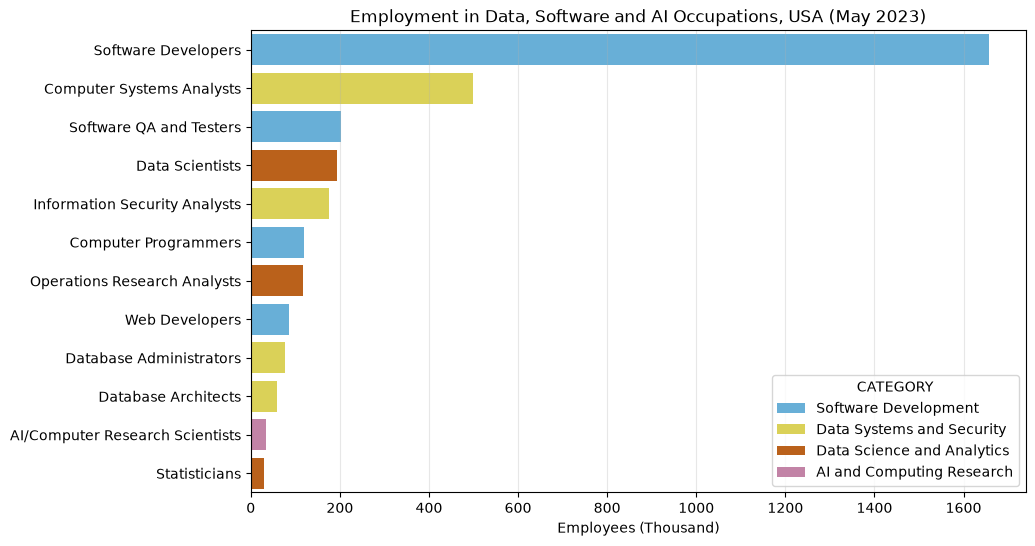

In [49]:
category_colours = {
    'Software Development': '#56B4E9', 
    'Data Systems and Security': '#F0E442', 
    'Data Science and Analytics' : '#D55E00', 
    'AI and Computing Research' : '#CC79A7'
}

national['EMP_THOUSANDS'] = national['TOT_EMP'] / 1000
national_sorted = national.sort_values(by='EMP_THOUSANDS', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data = national_sorted, x = 'EMP_THOUSANDS', y='ROLE', 
            hue='CATEGORY', palette = category_colours, dodge = False)

plt.title('Employment in Data, Software and AI Occupations, USA (May 2023)')
plt.xlabel('Employees (Thousand)')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)


In [50]:
#Creating supporting numbers: 
national['SHARE_PERCENTAGE'] = (national['TOT_EMP'] / national['TOT_EMP'].sum() * 100).round(2)
print(national.sort_values(by='SHARE_PERCENTAGE', ascending=False)[['ROLE', 'TOT_EMP', 'SHARE_PERCENTAGE']])

print((national.groupby('CATEGORY')['TOT_EMP'].sum() / national['TOT_EMP'].sum() * 100).round(2))


                                ROLE    TOT_EMP  SHARE_PERCENTAGE
149              Software Developers  1656880.0             50.96
135        Computer Systems Analysts   498810.0             15.34
150          Software QA and Testers   203040.0              6.24
165                  Data Scientists   192710.0              5.93
136    Information Security Analysts   175350.0              5.39
148             Computer Programmers   120370.0              3.70
161     Operations Research Analysts   117880.0              3.63
151                   Web Developers    85350.0              2.62
144          Database Administrators    76140.0              2.34
145              Database Architects    59920.0              1.84
138  AI/Computer Research Scientists    35210.0              1.08
163                    Statisticians    29950.0              0.92
CATEGORY
AI and Computing Research      1.08
Data Science and Analytics    10.47
Data Systems and Security     24.92
Software Development     

3.1.1 Visualisation's objective and rationale

Objective: This visualisation intended to provide a comparison between the number of employees in each selected occupation. Furthermore, it also displays how the workforce is distributed between the four categories that were created in the analysis phase. 

The reason for a barplot: one of the dimensions of the plot consists of categorical data (each occupation poses as one category, here placed on the y axis); The other dimension consists of numerical data (the number of employees, the x axis). This configuration suits a bar chart: each bar represents a category, and bar length measures the numerical variable. I used horizontal bars to ensure that the labels for the occupations are readable on the y axis, with no need to rotate them.   
The sorting of the data makes for the information to be read as a ranking, from biggest employment numbers to smallest, while the colour coding conveys an information of higher level: the category to which each occupation belongs. I have used the colour palette proposed by Okabe and Ito (2008), as a way to keep it readable even to colour-blind people, making it accessible. To keep the x axis's labels readable, the employment numbers are shown in thousands.

What can be learned with this visualisation: 
- Software development dominance: Software developers alone sum up to 50.96% of all the employees across the 12 occupations. When expanded to the higher level category, that includes Quality assurance and testers, as well as computer programmers and web developers, the category alone (Software Development) accounts for over 63% of employments. When dividing the total amount of Software Developers per the total amount of Computer Research Scientists, for example, the former is 47 times more numerous than the latter, which reaffirms how more common this occupation is compared to others in the technology field.
- By researching the BLS website, I was able to compare the Bureau's Standard Occupational Classification (SOC) 2018/2020 with its immediate predecessor, the SOC 2010. In the 2010 version, the occupation "Data Scientist" is not present, while Statisticians were already recognised as a professional occupation. However, my chart visually shows how Data Scientists outnumber Statisticians in an order of 6.4 to 1, approximately. Which could suggest a migration of professionals from one title to the other, however, that suggestion can only be fully proven under a diachronic study of that difference.
- A limitation of this study is that no AI occupation is mentioned by the BLS's SOC 2018/2020, hence professionals working with AI are all grouped under different titles, hence it is possible that professionals across all 12 occupations have jobs specifically related to Artificial Intelligence, but that information is impossible to extract without a new primary collection of Data.
- It is also noticeable how the dedicated research occupation is very small, amounting to only 1.08% of this workforce. This can be explained by two hypothesis: 1. the research workforce in 2023 really was significantly smaller than the other fields, or 2. that researchers were classified under other job titles, like Data Scientists, Programmers etc.
- Another limitation of this study is that BLS (2024b)'s table technical notes does not include in its survey self-employed, owners and partners in its statistics. When it comes to field like software developers, for example, where freelance work is not uncommon, the employment numbers are likely understated in the chart. 

3.2 Visualisation 2: Pie chart (Share of Employment by Category) 

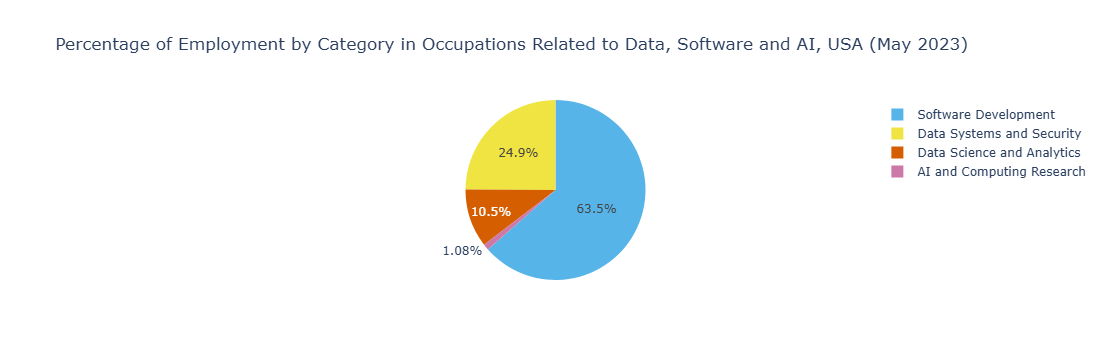

In [54]:
#grouping the data into their categories and summing up the total 
#employment per each 
category_emp = national.groupby('CATEGORY', as_index=False)['TOT_EMP'].sum()
category_emp

#Creating an interactive pie chart using plotly
pie_chart = px.pie(category_emp, names='CATEGORY', values='TOT_EMP', 
                   color='CATEGORY', color_discrete_map = category_colours,
                   title = 'Percentage of Employment by Category in Occupations Related to Data, Software and AI, USA (May 2023)',
                   labels={'CATEGORY':'Category', 'TOT_EMP':'Employees'})

pie_chart.show()

-Objective: In the section 2 of this assignment, during the preparation of the data, I have divided the 12 selected occupations amongst 4 categories: "Software Development"; "Data System and Security"; "Data Science and Analytics"; "AI and Computing Research". While my first chart compared each one of the occupations with one another, the following visualisation will explore the higher level: which percentage does each category represent of the total workforce of occupations related to Data,  Software and AI?

-Chart Justification: According to Spence (2005), the ideal use for pie charts is displaying a part in relation to the whole, particularly, when dealing with few proportions; proportions too numerous create a visually confusing chart, given that people cannot visualise angles to the same accuracy as lengths. The information which is intended to be demonstrated here fits these 2 conditions: it consists of few proportions (only 4 categories) that add up to a meaningful whole. I chose to use plotly to a create an interactive, visually compelling chart, using its hovering functionality and the colours used, were the same colour-blind-safe colours used in the horizontal bar chart, creating a cohesive visual information. 

-Learning:
1. The software development category was demonstrated to be the biggest portion of this specific workforce (AI, Data and Software Related occupations). Almost two at every three jobs fall into this category. 
2. When grouping the Data-focused categories together, they sum up to 35.4% of the whole, which represents a significant second position. and when compared against each other, it is noticeable there are more than double the jobs maintaining  and securing data infrastructure (24.9%, or 810220 jobs) than working in analytical or modelling jobs (340540 jobs, or 10.5%).
3. The research portion of the chart is much smaller than the other shares, representing only 1.08% of the total workforce in this sector (of every 92 jobs, only 1 falls within this category). This visualisation displays this information visually clearer than the horizontal bar chart, as there are fewer categories to compare than occupations, creating a more dramatic difference between the "AI and Computing" categories and the others. 
4. One limitation of this chart is that it only represents these proportions at a particular time. Hence it does not provide any diachronic information concerning each share. Again, this will be addressed in the challenge section. 

3.2.1 Supporting Pie Chart Visualisations


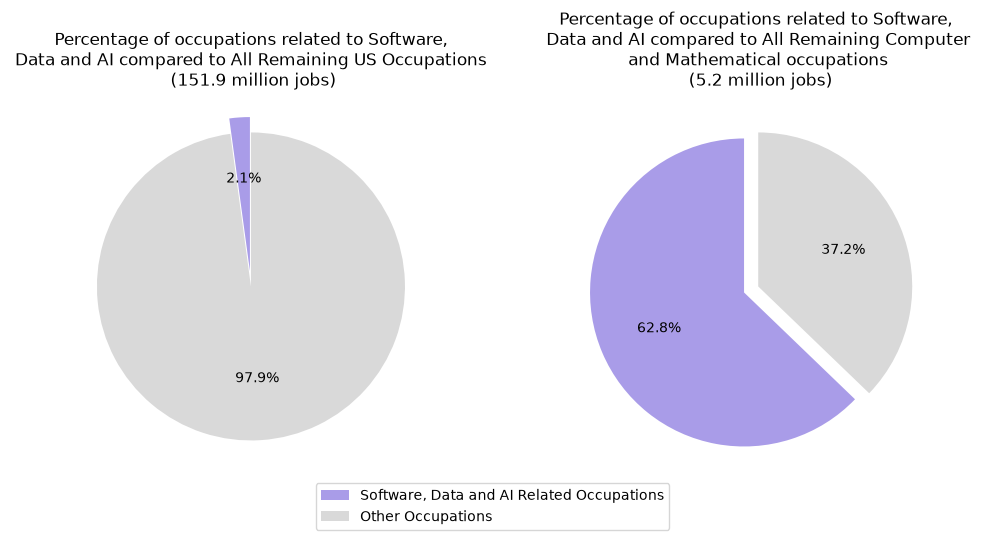

In [58]:
#Supporting Charts
total_emp_us = dataset_raw[(dataset_raw['AREA_TYPE'] == 1) & 
                                  (dataset_raw['I_GROUP'] == 'cross-industry') &
                                (dataset_raw['OCC_CODE'].isin(['00-0000', '15-0000']))]
total_emp_selected = national['TOT_EMP'].sum()

all_occ_us = total_emp_us[total_emp_us['OCC_CODE'] == '00-0000']['TOT_EMP'].sum()
occ_maths_and_comp = total_emp_us[total_emp_us['OCC_CODE'] == '15-0000']['TOT_EMP'].sum()

sizes_list_all = [total_emp_selected, all_occ_us - total_emp_selected]
sizes_list_mc = [total_emp_selected, occ_maths_and_comp - total_emp_selected]
labels_pc = ['Software, Data and AI Related Occupations', 'Other Occupations']
colours_pc = {'Violet' : '#A99CE8', 'Grey': '#D9D9D9'}

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.pie(sizes_list_all, colors=list(colours_pc.values()), autopct='%1.1f%%', 
        startangle=90, explode = (0.1, 0))
plt.title('Percentage of occupations related to Software,\n Data and AI compared to All Remaining US Occupations \n (151.9 million jobs)')

plt.subplot(1, 2, 2)
plt.pie(sizes_list_mc, colors=list(colours_pc.values()), autopct='%1.1f%%', 
        startangle=90, explode = (0.1, 0))
plt.title('Percentage of occupations related to Software, \n Data and AI compared to All Remaining Computer \n and Mathematical occupations \n (5.2 million jobs)')
plt.figlegend(labels_pc, loc = 'lower center')

plt.show()


- Objective: I have created these two supporting pie charts as a way to placing the selected workforce in context to the whole of the United States workforce and to the whole of Computer and Mathematical occupations. While the previous visualisation aimed to analyse the internal divisions of the selected employment group, these supporting charts will analyse it in terms of its size compared all other jobs (00-0000) and to its own parent category (15-0000). 

- Chart Justification: In this particular visualisation, I am demonstrating two relationships of the proportion-to-whole type, hence the necessity of using two pie charts. Placed in juxtaposition to one another, the two convey that, although a small part of the total US workforce, occupations related to Data, AI and Software represent a huge section (almost 63 percent) of jobs in its niche, Computer and Mathematical Jobs. The purple and grey colours were used to visually differentiate the portions analysed from the previously analysed categories.

- Learning:
  1. the worforce selected (12 occupations) amounts to solely 2.1% of the total US jobs: in other words, of every 47 employees, about only 1 falls within this group.
  2. The pie chart displaying the share of the 12 selected occupations in their parent category (Computer and Mathematical occupations) shows that approximately 9 of every 14 occupations in this broader group fall within the 12 selected occupations, which is  significant, confirming that the selection is quite comprehensive in terms of the workforce related to technology in the US, rather than representing a particular niche.
  3. Referring back to the table "Computer and Mathematical Occupations table", it is possible to notice that most of the occupations excluded from the selection are related to IT support or Network and Systems administrators, which according to the description provided in BLS's website, do not have a strong relation to AI, Data Analysis and Software Development. But still regarding the selection, I have excluded "Computer Occupations All Other", given that they lack the precision of an occupation definition, not matching any SOC code defined by the BLS. Any new profession related to AI, for instance, could fall here, being ignored by my analysis. This was a conscious decision, given the imprecise characteristic of the field.
  4. When combining visualisation 2 with supporting pie charts, it is possible to notice that research occupations in Computing consist of 1.08% within its own niche, which is already a small part of all of the US workforce (2.1%). Hence, it is possible to conclude that research occupations in computing are only about 0.02% of the whole nation's workforce, despite being an important innovation driver in its field (Cinus et al, 2025).  
   

3.3 Visualisation 3: Grouped bar chart - the distribution of annual salary by each occupation

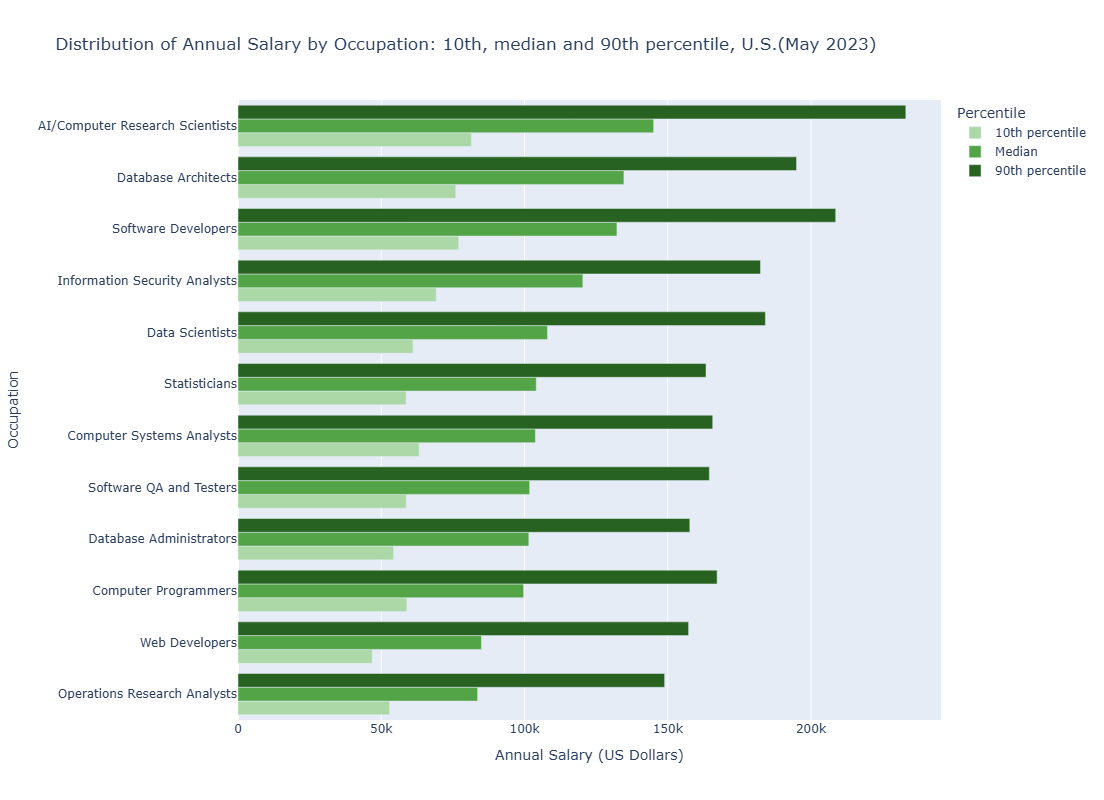

In [61]:
annual_salary = national[['ROLE', 'A_PCT10', 'A_MEDIAN', 'A_PCT90']].sort_values(by='A_MEDIAN')
annual_salary = annual_salary.rename(columns={'A_PCT10' : '10th percentile', 'A_MEDIAN':'Median', 'A_PCT90' : '90th percentile'})

as_to_long = annual_salary.melt(id_vars='ROLE', var_name='Percentile', value_name='Annual Salary (US Dollars)')

p_colours_list = { '10th percentile': '#ACD8A7', 'Median' : '#52A447', '90th percentile': '#276221'}

salaries_figure = px.bar(as_to_long, x='Annual Salary (US Dollars)', y='ROLE', color='Percentile',
                         barmode='group', orientation='h', color_discrete_map = p_colours_list, labels={'ROLE': 'Occupation'}, 
                         title='Distribution of Annual Salary by Occupation: 10th, median and 90th percentile, U.S.(May 2023)')
salaries_figure.update_layout(height=800)
salaries_figure.show()

- Objective: while the previous charts until this section have delved into the employment numbers concerning the 12 selected occupations, this grouped bar chart examines each occupation's pay and highlights the variation of salary within each career, and between one another. To summarise the internal pay range of an occupation, I have used three percentiles: 10th (someone receiving a very likely entry-level salary), Median (the typical worker in that position) and 90th (top earners for that occupation).

- Chart Justification:
  1. The use of a bar chart can be justified in this case, as it was with the visualisation number 1, by the presence of a categorical variable as one of the dimensions (y).  However, a grouped bar was the correct choice in this case, given that the x axis consists of three distinct, though related, numerical variables (they're all salaries, but at distinct percentiles). The juxtaposition of the groups of bars allows for easy comparison between occupations, while having the bars side-by-side within the groups allows for the clear visualisation of the salary range within each of them.
  2. Concerning the average salary measure, I have selected the median. Observing the table in my preparation phase, I have noticed that the mean salary of each occupation is always higher than the median, indicating that the salary data is skewed to the right. That makes sense, considering that a few outliers make significantly higher wages than the rest of employees for each category.
  3. To display the range of salaries within each occupation, I have chosen to use only 3 percentiles, to avoid cluttering the y axis witth excessive information. Had the table contained information of each individual salary, a box plot could have been used for this distribution chart, however, under the data's limitation, I think the bar chart was a way to represent it truthfully, without assuming any non-collected data.
  4. I have used different shades of the same hue to represent the different percentiles given the natural sequential aspect of the data (the shade scale, light to dark, representing the percentile scale, the lowest to the highest).
  5. By using an interactive plotly chart, I have created a very user-friendly experience, in which a reader has access to the exact salary by hovering the mouse over the bar.

- Learning:
  1. This plot allows for a clear visualisation of the highest earning occupation group, and that is AI/Computer Research Scientists. These workers earn greater salaries in every percentile when compared to the others. When crossing this information with visualisations 1 and 2 (which both display the research field as being the smallest workforce amongst the selected), one possible explanation arises: demand for a scarce type of professional leads to bigger pays. It is important to note, however, that this is a conjecture guided by the data, but not proven. More research would be necessary to investigate if this is truly the explanation.
  2. The gap between the highest earning occupation and the lowest one is huge. When comparing the average worker in AI/Computer research (145 080 dollars) and the typical Operations Research Analyst (83 640 dollars), the former earns approximately 73% more than the latter.
  3. This visualisation allows for the conclusion that occupation is not necessarily a completely accurate predictor of pay, given that when observing the top salaries of each occupation, they are always higher than any median pay (the lowest 90th percentile pay is 148 920 dollars, which is higher by 3840 dollars than the typical Computer Research Scientist). The fact that the variation of pay is bigger internally, for each occupation, than when comparing them with one another supports the limitation of this parameter as a predictor of wage: to illustrate that, the difference in salary between the best paid Operations Research Analysts and the worst paid is of 95 990 dollars, which is greater than the difference between the highest and lowest medians  (AI/Computer Research Scientist and Operations Research Analyst respectively) by 34 550 dollars.
  4. When analysing the inequality of pay relatively, the web developer career path has the most unequal pay: the top earners (90th percentile) make 3.4 times more money than workers in the 10th percentile. But the absolute difference is at the most impressive value for AI/Computer researchers: the 90th percentile workers make 151 660 dollars more than the workers in the 10th percentile.
  5. When considering the categories I have defined as part of my analysis, it is possible to reach the conclusion that category does not constitute a good predictor of salary. For instance, the category Data Systems and Security contains two diametrically opposed examples: a Database Architect earns the second highest wage (when taking the median as parameter, 134 700 dollars), while Database administrators, in the same category, only make 101 510 dollars, the 4th lowest median salary. And that pattern is not solely observed for that category, the wages vary greatly within them. The Software development category includes both Web Developers (earning only just under 85 thousand dollars, the second lowest median pay) and Software Developers (who earn  132 270 dollars, being the third highest median pay). 

3.4 Visualisation 4: Comparing median pay across different metro areas using a box plot. 

In [65]:
# Box Plot - Comparing Median Pay across all metro areas - cleaning and exploring  

#Cleaning the data from the metropolitan rows table. 
#first, I use the dropna function to remove the rows where the median wage is blank
sal_metro = metropolitans.dropna(subset=['A_MEDIAN'])
#printing it to compare with previous shapes results, and analyse how many rows were dropped. 
print(metropolitans.shape, sal_metro.shape)
#the next line, prints the number of metropolitan areas in which the specific roles appear
print(sal_metro['ROLE'].value_counts())

#In the next line, I order the national list of roles by descending order of median pays
#that is stored in the list desc_role. 
desc_role = list(national.sort_values(by='A_MEDIAN', ascending=False)['ROLE'])
desc_role


(2555, 20) (2531, 20)
ROLE
Software Developers                378
Computer Systems Analysts          362
Data Scientists                    244
Computer Programmers               234
Information Security Analysts      227
Software QA and Testers            216
Database Administrators            198
Web Developers                     196
Operations Research Analysts       190
Database Architects                129
Statisticians                       91
AI/Computer Research Scientists     66
Name: count, dtype: int64


['AI/Computer Research Scientists',
 'Database Architects',
 'Software Developers',
 'Information Security Analysts',
 'Data Scientists',
 'Statisticians',
 'Computer Systems Analysts',
 'Software QA and Testers',
 'Database Administrators',
 'Computer Programmers',
 'Web Developers',
 'Operations Research Analysts']

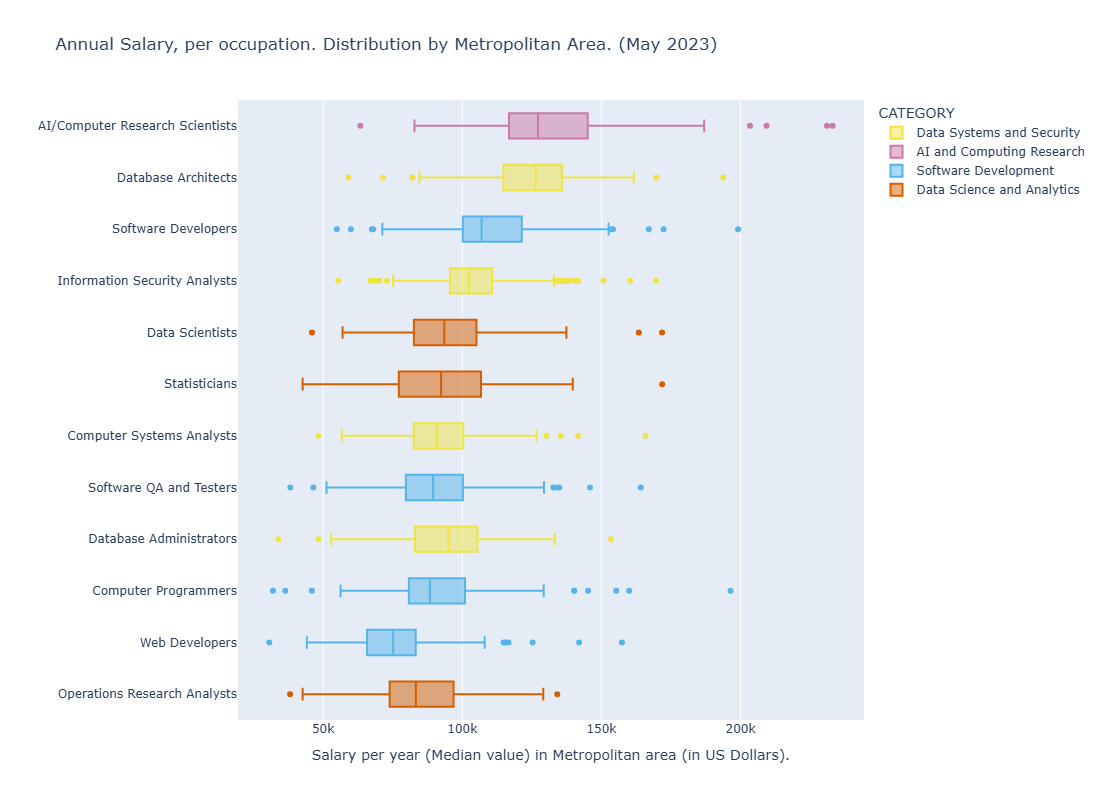

In [66]:
#Creating the chart itself 

#Plotting the box chart. 
#each box chart represents the distribution of median salary (A_MEDIAN) 
#per occupation, across different metropolitan areas. 
box_chart = px.box(sal_metro, x='A_MEDIAN', y = 'ROLE', color = 'CATEGORY', color_discrete_map = category_colours,
                  hover_data=['AREA_TITLE', 'TOT_EMP'], labels={'A_MEDIAN' : 'Salary per year (Median value) in Metropolitan area (in US Dollars).', 'ROLE':''}, 
                   category_orders={'ROLE': desc_role},
                   title='Annual Salary, per occupation. Distribution by Metropolitan Area. (May 2023)')
#Box mode overlay was added to fix the misalignment of the boxes with their labels, and to adjust box width (v-s-labs, 2016). 
box_chart.update_layout(height=800, boxmode = 'overlay')
box_chart.show()

In [67]:
#Supporting numbers: 

#Pure Numbers with no visualisation: number of metropolitan areas per occupation, its min, Q1, median, Q3 and Max value. 
sal_metro.groupby('ROLE')['A_MEDIAN'].describe().round(2).sort_values(by = '50%', ascending=False)


,count,mean,std,min,25%,50%,75%,max
ROLE,,,,,,,,
AI/Computer Research Scientists,66.0,134349.70,33574.64,63390.0,116937.5,127200.0,145077.5,233110.0
Database Architects,129.0,126131.16,20346.56,59080.0,115020.0,126420.0,135770.0,193780.0
Software Developers,378.0,110484.58,16624.18,54930.0,100210.0,106940.0,121375.0,199100.0
Information Security Analysts,227.0,104197.14,16884.47,55390.0,95680.0,102390.0,110315.0,169620.0
Database Administrators,198.0,94883.13,16759.27,33900.0,83010.0,95010.0,105450.0,153430.0
Data Scientists,244.0,95703.48,17879.58,46010.0,82655.0,93550.0,105025.0,171800.0
Statisticians,91.0,92297.69,22088.03,42640.0,77440.0,92390.0,106075.0,171840.0
Computer Systems Analysts,362.0,92072.51,13411.88,48250.0,82582.5,90845.0,100357.5,165870.0
Software QA and Testers,216.0,90076.67,17051.77,38230.0,79782.5,89535.0,100155.0,164160.0


In [68]:
sal_metro.sort_values(by='A_MEDIAN', ascending=False)[['AREA_TITLE', 'ROLE', 'A_MEDIAN', 'TOT_EMP']].head(10)


,AREA_TITLE,ROLE,A_MEDIAN,TOT_EMP
234985,"Seattle-Tacoma-Bellevue, WA",AI/Computer Research Scientists,233110.0,2410.0
234984,"Santa Maria-Santa Barbara, CA",AI/Computer Research Scientists,231050.0,110.0
234983,"San Jose-Sunnyvale-Santa Clara, CA",AI/Computer Research Scientists,209340.0,2210.0
234982,"San Francisco-Oakland-Hayward, CA",AI/Computer Research Scientists,203400.0,1540.0
237167,"San Jose-Sunnyvale-Santa Clara, CA",Software Developers,199100.0,96590.0
236829,"Seattle-Tacoma-Bellevue, WA",Computer Programmers,196420.0,2940.0
236232,"San Jose-Sunnyvale-Santa Clara, CA",Database Architects,193780.0,960.0
234955,"Idaho Falls, ID",AI/Computer Research Scientists,186930.0,NaN
234931,"Albany-Schenectady-Troy, NY",AI/Computer Research Scientists,176770.0,120.0
234941,"Buffalo-Cheektowaga-Niagara Falls, NY",AI/Computer Research Scientists,175840.0,30.0


- Objective:
  1. With visualisation 3, I was able to perceive the variation of salary within each role and also compare each role with one another, however it was impossible to know the reason of tht internal variation. One possible explanation, could be the location. Thinking of that, I decided to use box plots to assess how much variation of median salary (a typical worker) there is across the different metropolitan areas. The table has different median salaries assigned to each role in different rows depending on the metropolitan area value, hence a role which has A_MEDIAN not blank across 378 metropolitan areas (like the software developer role, as shown above in my cleaning and exploring commands), will have 378 salary values, hence creating enough data points to plot a distribution. One limitation I have to admit is that, for some occupations (like AI/Computer Research Scientists), many metropolitan areas had to be dropped due to their median salary value being blank. For the mentioned occupation, for example,  I was only left with 66 metropolitan areas to work with, which could influence the trustability of the chart, due omission of data.
  2. It is important to notice that with this distribution, I am analysing and assessing the typical places and which places are outliers, and not the typical workers. Each metropolitan area is treated as having the same weight independently of the amount of workers in that area. That will allow me to understand how the typical wage can vary geographically.

  - Justification:
    1. Box plot was used given that I had enough data points in the A_MEDIAN axis (x) to create a distribution, allowing me to analyse how that particular value vary across different geographical locations.
    2. Again a horizontal orientation was chosen to allow for the readability of the occupation titles (distributed vertically, on the y axis).
    3. The order of this chart follows the one in visualisation 3, which allows for a better comparison between charts.
    4. To create a visual cohesion between this chart and charts 1 and 2, I have used the same category colour code.
    5. The hover function, when used in the outliers value, allows the reader to see which specific metropolitan area has a median payment way above or way under the typical areas.
   
    - Learning
   1. It is possible to assess how much the location matters in terms of the typical pay by visually inspecting the width of the box. The wider the box, it indicates that the interquartile 50% of the data (the typical median salary when taking into consideration only the variation across metro areas) is more spread out.
   2. By observing the boxes, I noticed that geographical location influences salaries significantly. For example, even in the thinnest box (Information Security Analyst), hence the occupation with smallest spread of the typical median salary per metro area, there is quite a substantial difference between its min and max pays (the outlier metro areas): 169 620 / 55 390 = 3.06, approximately. While in the occupation with the biggest variation across metropolitan areas (Computer Programmers), that ratio is of approximately 6.1 times (196 420 in Seattle metro, while 31 980 in Ponce).
   3. The existence of specific tech hubs is highlighted by the box plots. In 75% of the occupations (9 of the total 12), the same metropolitan areas represent the location with biggest pay (the highest outliers), this metropolitan area is San Jose-Sunnyvalley-Santa Clara, regions in the West Coast well known for being hubs of the tech industries. This finding aligns and supports the justification in section 2 (Data Cleaning and Preparation) to keep the outliers, given that they represent meaningful differences in salary rather than being a data collection error.
   4. When analysing the range of pay in each occupation in this plot (which is based on location distribution), it is possible to notice that the widest range happens for AI/Computer Research Scientists (a range of 169 720 US dollars). The box, which displays the interqueartile range is also the second widest amongst all occupations (only behind Statisticians), presenting a range of 28 140 US Dollars. This means that the pay for AI/Computer Research Scientists vary greatly depending on geographical location. That suggests that at least part of the internal variation of salary for this occupation is due to geographical location, rather than seniority. A limitation when it comes to this occupation, is that the median salary data (A_MEDIAN) is available for only 66 metropolitan areas, and the lack of data might have interfered with the accuracy of these claims.
   5. When comparing the order in which the occupations appear on the box plot (order by national median salary) and the order that they appear in my supporting table (or simply observing the position of the IQR box in the plot), it is possible to assess that the typical metro area pattern aligns very closely with the national pattern: the typical metropolitan area pay is the highest for AI/computer Research, Database Architects and Software Developers, while the lowest values include Web Developers and Operations Research Analysts. There is one very visible exception, however: the typical metropolitan pays  Database Administrators a salary of 95 010 US dollars, placing it in the 5th position, while in visualisation 3, analysing the national medians, it ranked 9th place out of the 12 occupations.
   6. When comparing typicality in terms of the workers and in terms of the metropolitan regions, it is possible to notice that the typical worker earns more (the median salary nationally) than what the typical metropolitan region pays (the median value of A_MEDIAN across metropolitan regions). For example, the typical Software Developer earns 132 270 US Dollars, while the pay for a typical metropolitan region for this occupation is of 106 940 US Dollars. That happens, because as mentioned before, in visualisation 4, every metropolitan area is given the same weight, independently of the workforce numbers, while the national median is completely guided by the salary by worker. This gap indicates that the workforce is more concentrated in the high-paying tech hubs, which makes sense: higher pays attracting more workers, leading to a more competitive market and higher pays, which feeds back into the cycle.
      

3.5 Visualisation 5: A scatter plot comparing the size of the workforce (employment) against the Median Salary across metropolitan areas in the US (May 2023)

In [71]:
#The scatter plot needs to take one role at a time, as it would be very confusing to have 
#all occupations at the same time, which would defeat the purpose of the visualisation. 
# in this cell I create the scattered dictionary object, which I will use to build
#my plots for each occupation on a loop
scattered = {}
for name in role_names:
    name = role_names[name]
    scattered[name] = metropolitans[metropolitans['ROLE'] == name ].dropna(subset=['TOT_EMP', 'A_MEDIAN', 'LOC_QUOTIENT'])

#testing if it worked, by printing name and the shape of scattered. 
for name in scattered:
    print(name, scattered[name].shape)

Computer Systems Analysts (360, 20)
Information Security Analysts (225, 20)
AI/Computer Research Scientists (64, 20)
Database Administrators (197, 20)
Database Architects (128, 20)
Computer Programmers (230, 20)
Software Developers (378, 20)
Software QA and Testers (213, 20)
Web Developers (183, 20)
Operations Research Analysts (184, 20)
Statisticians (90, 20)
Data Scientists (242, 20)


In [72]:
#Now I am going to create the chart itself on a loop:
#I am using the logarithmic scale for the x axis because TOT_EMP is extremely right skewed,
#so to accommodate metro areas with a bigger number of employees, the scale was streched out, 
#which made it difficult to see any pattern in the overall data (most of it was squeezed to the left side). 
# The log transformation method handles this right-skewedness properly because is appropriate
#to reduce the variability of the data, specially when it contains meaningful outliers (Ravulakollu, 2023).
figure_scatter = {}
for data in scattered:
    figure_scatter [data] = px.scatter(scattered[data], x = 'TOT_EMP', y= 'A_MEDIAN', log_x = True, size= 'LOC_QUOTIENT', color = 'CATEGORY', 
              color_discrete_map = category_colours, hover_name = 'AREA_TITLE', hover_data=['LOC_QUOTIENT'],
              labels={'TOT_EMP':'Workers employed in metropolitan area (log scale)', 'A_MEDIAN':'Median Annual Salary', 
                      'LOC_QUOTIENT': 'Location quotient', 'CATEGORY': 'Category'}, 
              title= f'{data}: Workforce size vs Median annual Salary across metropolitan regions')
    figure_scatter[data].update_layout(height= 700)
    

Instead of showing the scatter plots in a loop (that would me much quicker), I have decided to give each one their own cell. That supports better readability, because when plotting them in one cell, Jupyter notebook created a scroll box, that made it really difficult to visualise each plot completely. 

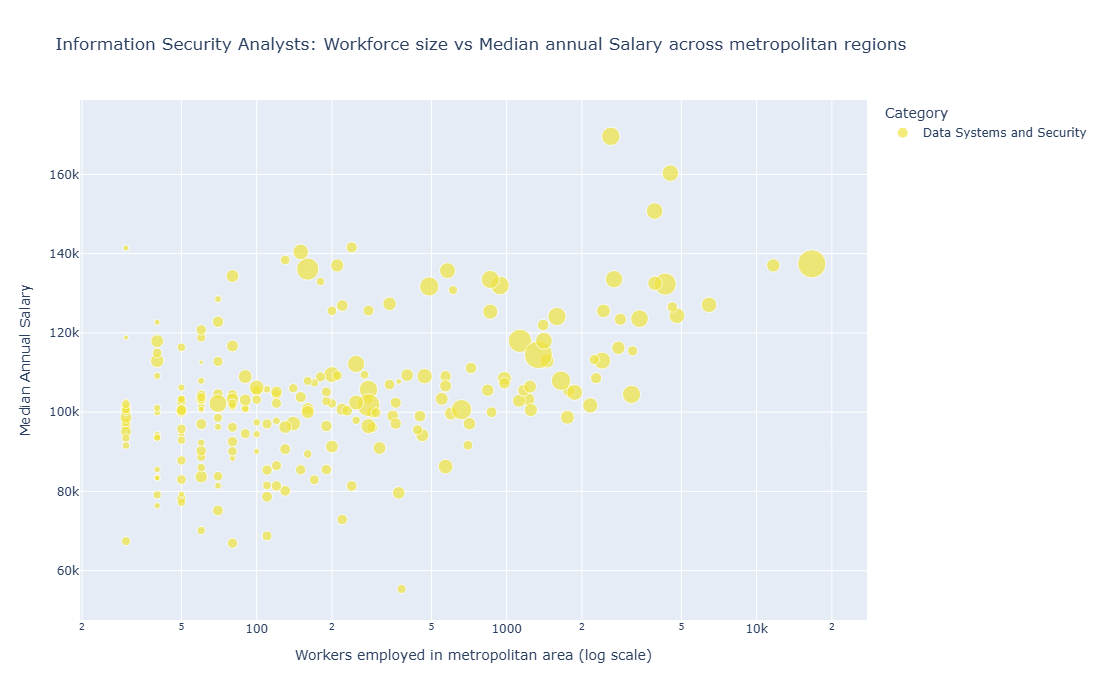

In [74]:

figure_scatter['Information Security Analysts'].show()

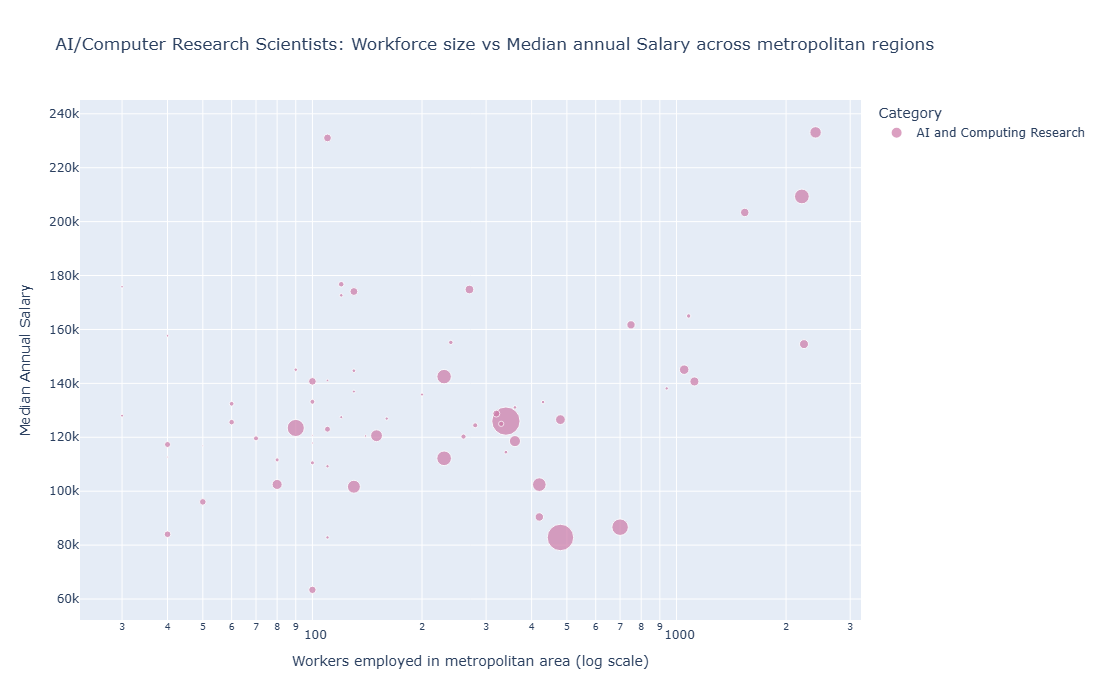

In [77]:
figure_scatter['AI/Computer Research Scientists'].show()

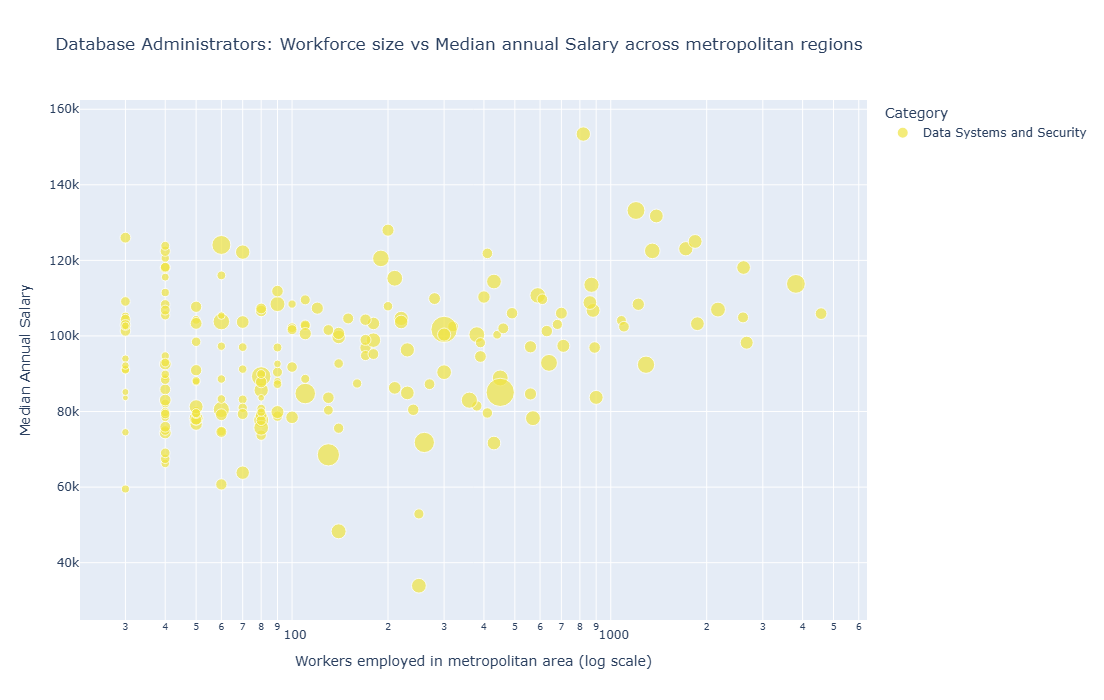

In [78]:
figure_scatter['Database Administrators'].show()

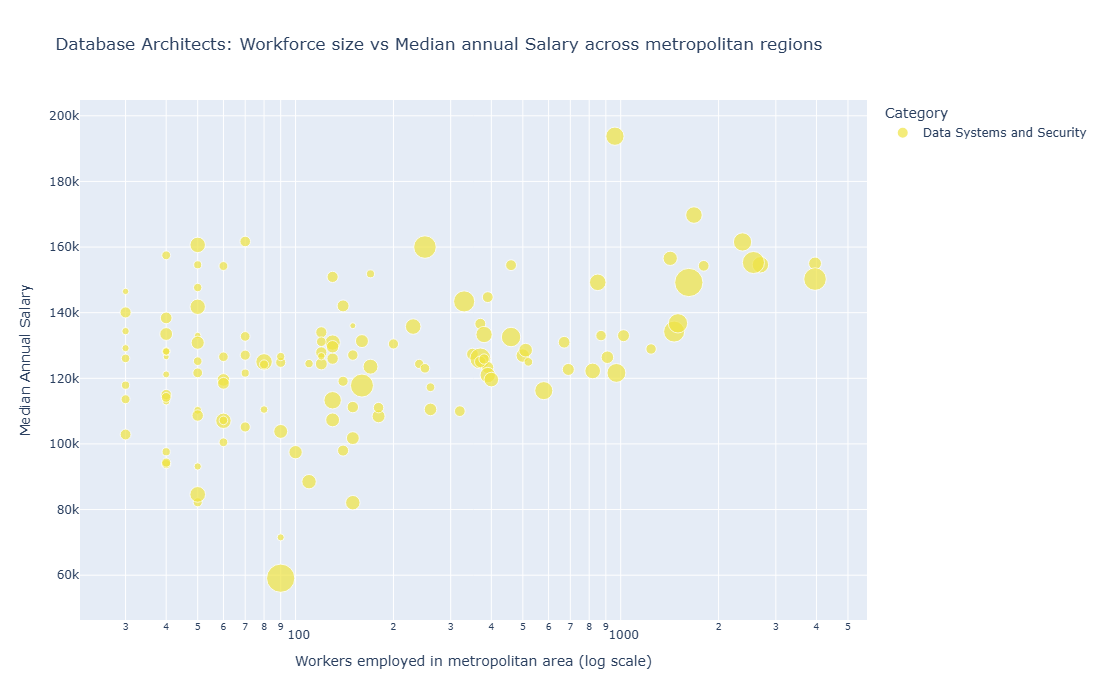

In [79]:
figure_scatter['Database Architects'].show()

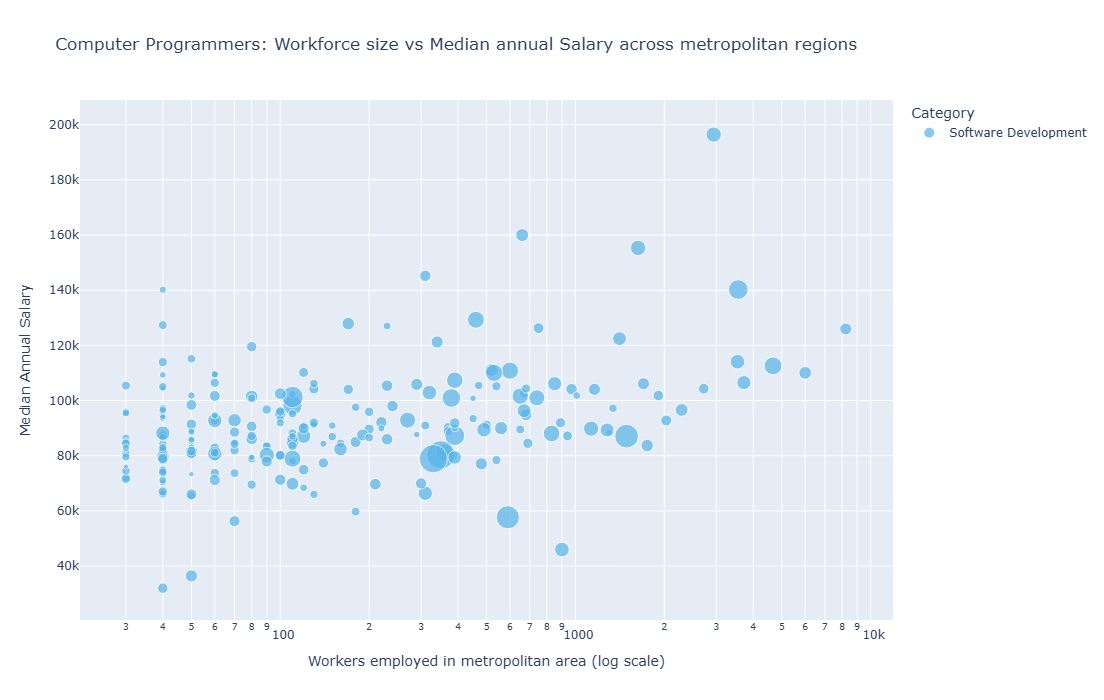

In [80]:
figure_scatter['Computer Programmers'].show()

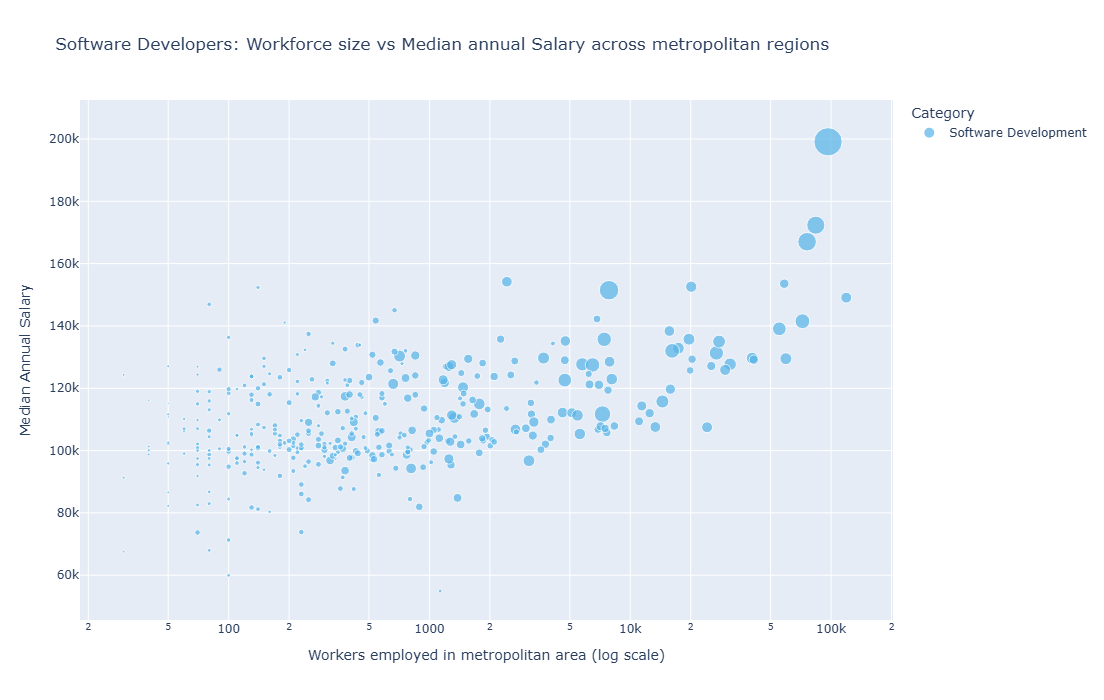

In [83]:
figure_scatter['Software Developers'].show()

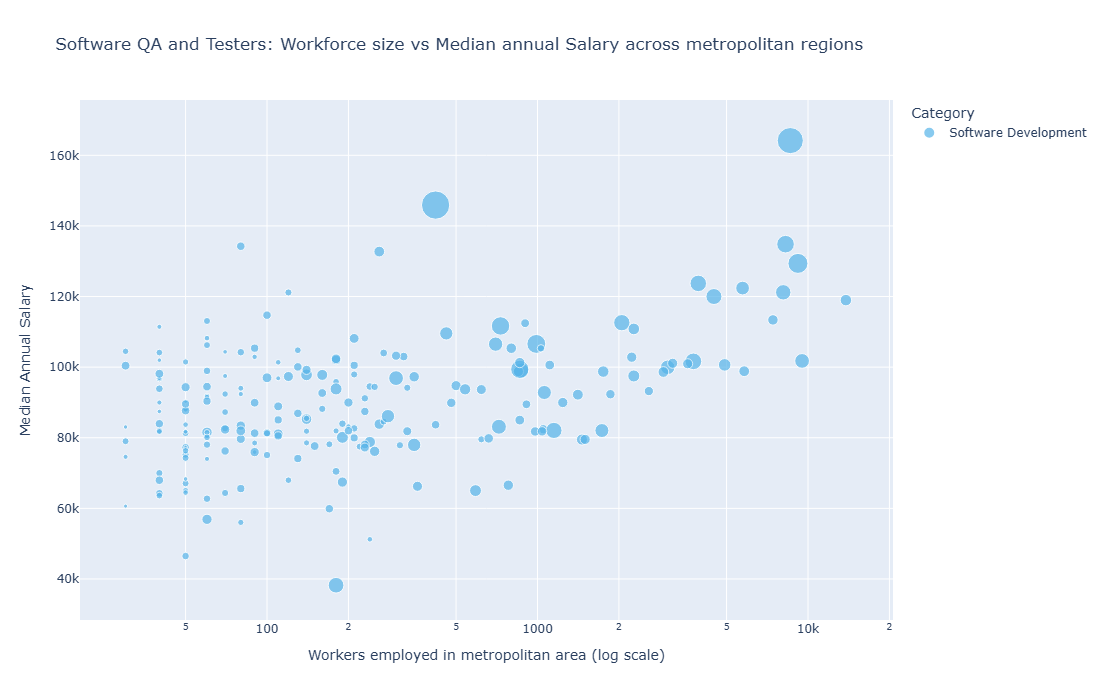

In [87]:
figure_scatter['Software QA and Testers'].show()

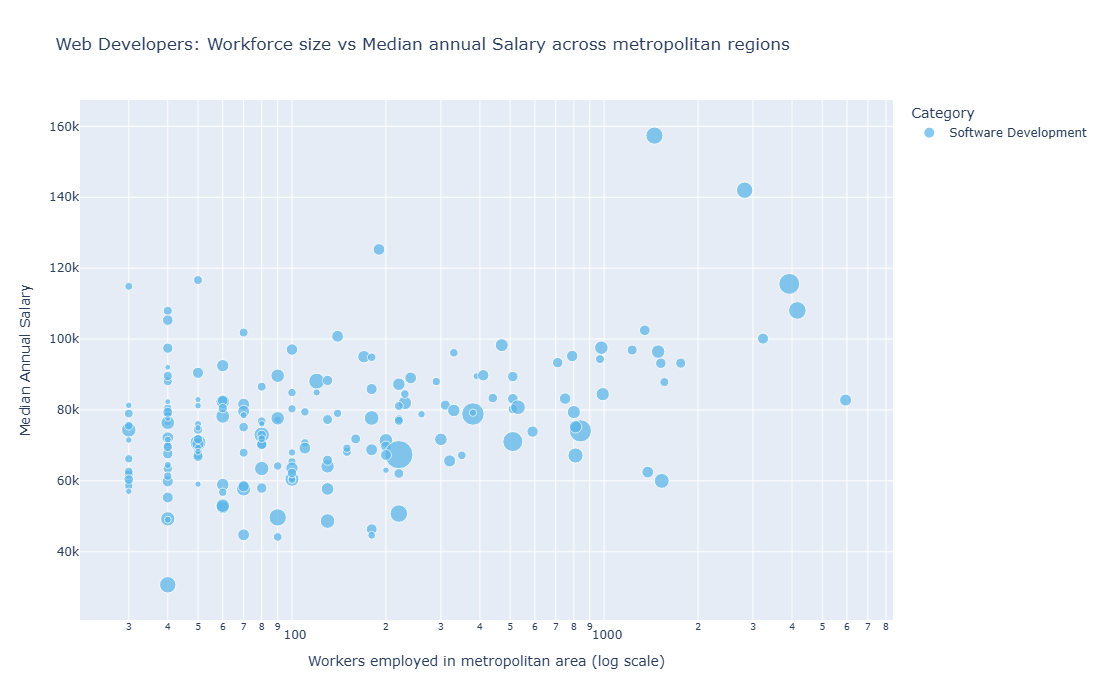

In [89]:
figure_scatter['Web Developers'].show()

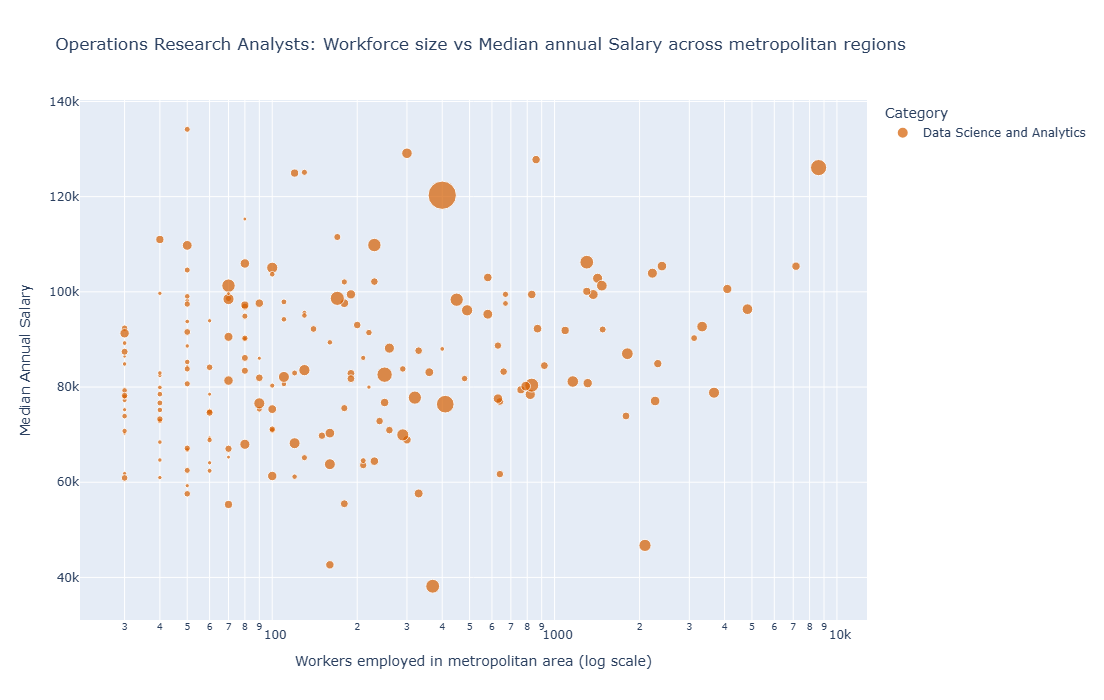

In [90]:
figure_scatter['Operations Research Analysts'].show()

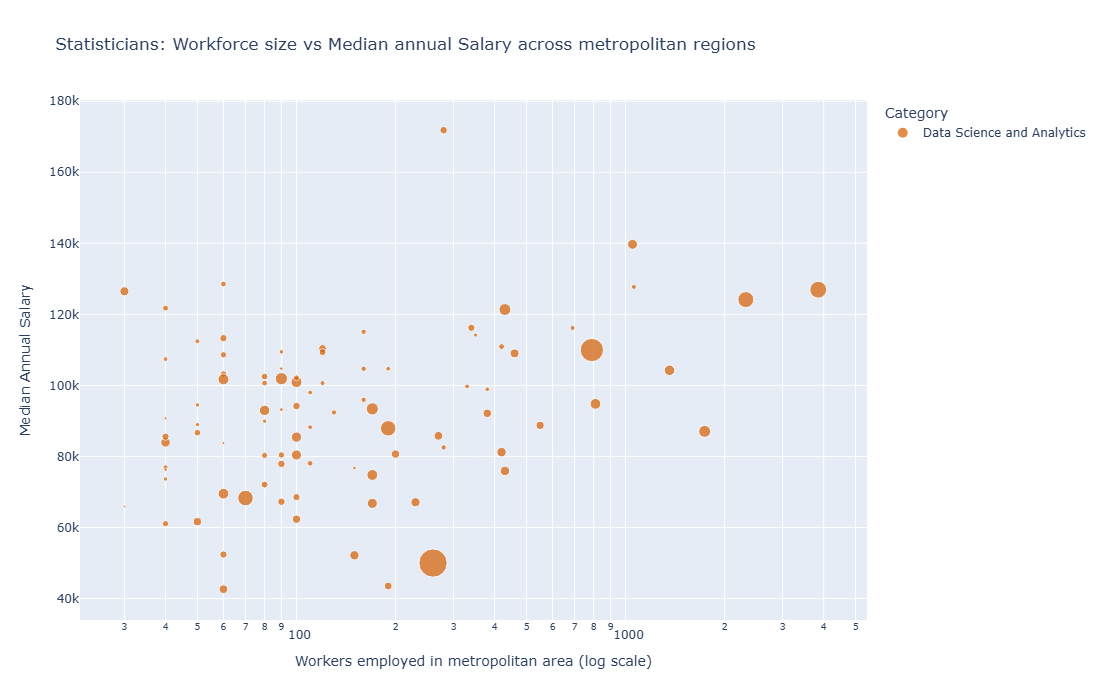

In [92]:
figure_scatter['Statisticians'].show()

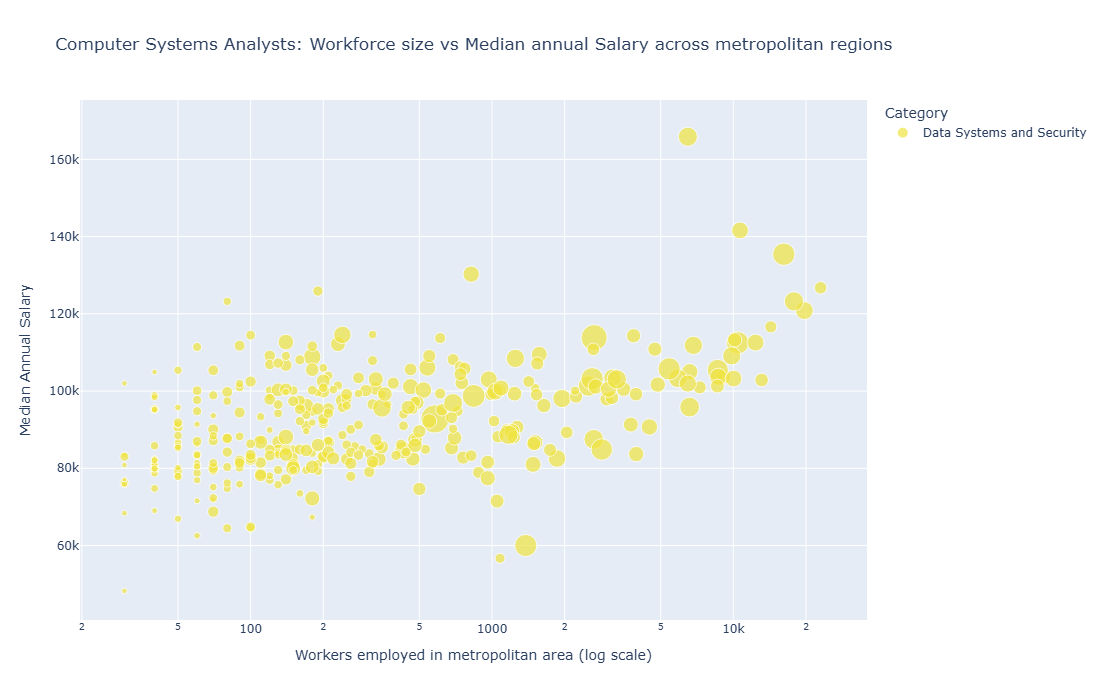

In [95]:
figure_scatter['Computer Systems Analysts'].show()

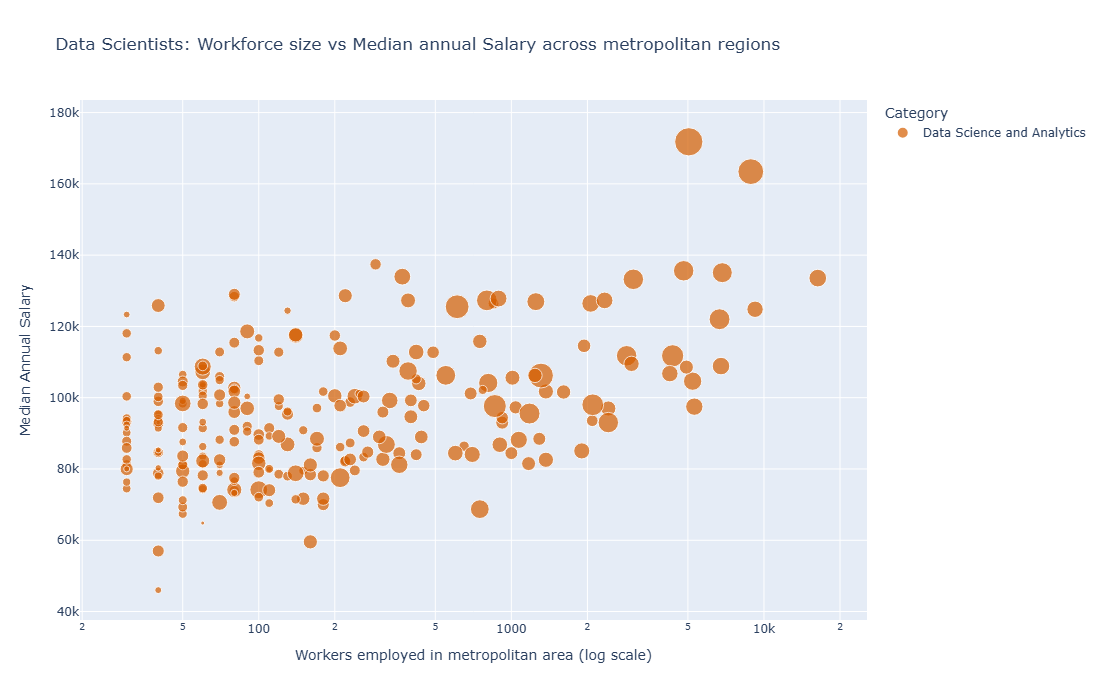

In [96]:
figure_scatter['Data Scientists'].show()

In [99]:
#Creating supporting numbers chart: 
for name in scattered:
    correlations = scattered[name][['TOT_EMP', 'A_MEDIAN', 'LOC_QUOTIENT']].corr()
    
    
    print(name, '| Total Metros:', len(scattered[name]),
          '| r(employment, salary) =', round(correlations.iloc[0,1],2),
          '| r(location quotient, salary) =', round(correlations.iloc[2,1],2))
    

Computer Systems Analysts | Total Metros: 360 | r(employment, salary) = 0.47 | r(location quotient, salary) = 0.39
Information Security Analysts | Total Metros: 225 | r(employment, salary) = 0.42 | r(location quotient, salary) = 0.42
AI/Computer Research Scientists | Total Metros: 64 | r(employment, salary) = 0.49 | r(location quotient, salary) = -0.12
Database Administrators | Total Metros: 197 | r(employment, salary) = 0.3 | r(location quotient, salary) = 0.06
Database Architects | Total Metros: 128 | r(employment, salary) = 0.43 | r(location quotient, salary) = 0.12
Computer Programmers | Total Metros: 230 | r(employment, salary) = 0.38 | r(location quotient, salary) = 0.1
Software Developers | Total Metros: 378 | r(employment, salary) = 0.5 | r(location quotient, salary) = 0.52
Software QA and Testers | Total Metros: 213 | r(employment, salary) = 0.48 | r(location quotient, salary) = 0.49
Web Developers | Total Metros: 183 | r(employment, salary) = 0.39 | r(location quotient, salar

- Objective:
In visualisation 4, I found that the annual median salary for a particular occupation was always bigger than the pay for a typical metropolitan area (median of metropolitan area median salaries). When facing these numbers, my conjecture was that the majority of the workforce was concentrated in metropolitan areas where the pay was higher (possibly tech hubs). The scatter plots in visualisation 5 are intended to investigate this conjecture directly. Is salary linked to the concentration of an occupation locally?

- Justification for scatter plot: 
1. Scatter plots are ideal to demonstrate relationships with 2 numerical dimensions. In this case the 2 axis consist of the size of the workforce (x: number of employees for that occupation, transformed into a logarithmic scale) and the median annual salary (axis y). Each one of the dots in the 2D plane stands for one metropolitan area, positioned by the two dimensions mentioned above.
2. I also included a third variable to the visualisation. The point size is determined by the Location Quotient. BLS's table description explains LOC_QUOTIENT as being the ratio between an occupation's share of employment in that particular area to its share in the country as whole. Hence, a higher location quotient of an occupation for a particular metropolitan area indicates that the role is more common in that metro area than it is in the rest of the country. I included this variable as a way to identify tech hubs, creating a visually identifiable difference between them and cities which have a huge workforce purely given to their large population.
3. I decided to create 12 different scatter plots for readability: too many points, representing different occupations would have occluded any pattern.
4. I decided to use a logarithmic scale on the x axis given the intense right-skewedness of the data. A previous version without this transformation did not reveal any pattern, given that a big portion of the data was compressed on the left side of the chart.
5. By using the hover function, I have made the chart interactive. The reader can identify each metropolitan region by hovering the mouse over the points.

- Learning:
  1. By observing all 12 scatter plots, a moderate positive correlation is noticeable  when it comes to the size of the market (amount of Employees in a particular metropolitan area) and the median annual salary. The supporting correlations table corroborates that finding. The correlation coefficient (r) varies from +0.24 (for the Operations Research Analyst occupation) to +0.5 (for the Software Developers occupation). Other weak correlations are for the occupations Statisticians (r = 0.32) and Database Administrators (r = 0.30), while AI/Computer Research Scientists, Software QA and Testers and Computer Systems Analysts exhibit coefficients closer to 50% (0.49, 0.48 and 0.47 respectively). Therefore, the charts allow for the clear conclusion that workforce size for a location indeed affects its pay, however, only moderately: it does not account for the variation entirely.
  2. Despite the positive correlation between market size and salary, the charts also allow for the surprising conclusion that seldom the metropolitan area with the biggest market is the best-paying one. The only time market size and best salary coincide is in the field of AI/Computer Research Science, in which Seattle is both the biggest market and the highest paying metropolitan area. For comparison, New York is the biggest market for 7 occupations (16 330 Data Scientists, 5 940 Web Developers, 13 810 Software QA Testers, 119 010 Software Developers, 8 230 Computer Programmers, 3 960 Database Architects and 4 570 Database Administrators), however, in none of them, this metropolitan region is the highest paying area. San Jose, on the other hand, is never the biggest market, nevertheless, it is the highest paying metropolitan area in nine of the 12 occupations.
  3. The location quotient, or in other words, how concentrated that occupation is in a particular metropolitan area, is not always correlated to pay. Observing the charts give us a hint at that, given that the points do not obviously seem to grow in a left-to-right and upwards pattern. To some occupations, a positive correlation as strong as the one noticed for market size and pay was identified, these are: Information Security Analysts (r = 0.42), Data Scientists (r = 0.44), Software QA Testers (r = 0.49) and Software Developers (r = 0.52). Other occupations exhibit a very weak positive correlation (Database Administrators, r = 0.06; Computer Programmers, r = 0.1; Database Architects, r = 0.12). For 2 of the occupations the correlation is negative, though still quite weak (Statisticians, r = -0.09; AI/Computer Research Scientists, r = -0.12). The occupations exhibiting weak positive correlation or even slightly negative correlation, display their biggest location  quotient in smaller regions, for example, Jefferson City - Missouri shows the highest location quotient for Statisticians, however, despite its only 260 workers and a pay of only 50 000 US dollars. This lack of strong positive correlation could be interpreted as being a result of government infrastructure (Jefferson City is the capital of its state, Missouri) or universities creating opportunities which do not pay as much as the big tech hubs like San Jose, California, but still enough to drive the concentration of tech workers in that area.
  4. When it comes to AI/Computer Research, being in a big hub predicts better salaries better than being in a area with high concentration. California-Lexington Park is the metropolitan area with the biggest location quotient for this occupation (30.78), however the salary is only 126 000 US Dollars, which is 45.9% lower than the pay in the biggest market for this occupation, which is Seattle and 39.8% lower than the pay in San Jose. Hence being in a bigger commercial tech hub is more linked to bigger payments than being in a highly specialised location.
  5. A limitation: throughout this learning section, I have been proposing possible causes for the correlations found, however, the charts do not confirm any of them. The charts only display correlations, and it is not possible to assess the causes from these visualisations alone. The proposed hypothesis require further investigation.    

3.5.1 A slightly different plot with the same variables: 3D Scatter Plot

In this extra visualisation, instead of using point size to represent location quotient, it is plotted as a 3rd axis. 

(64, 20)


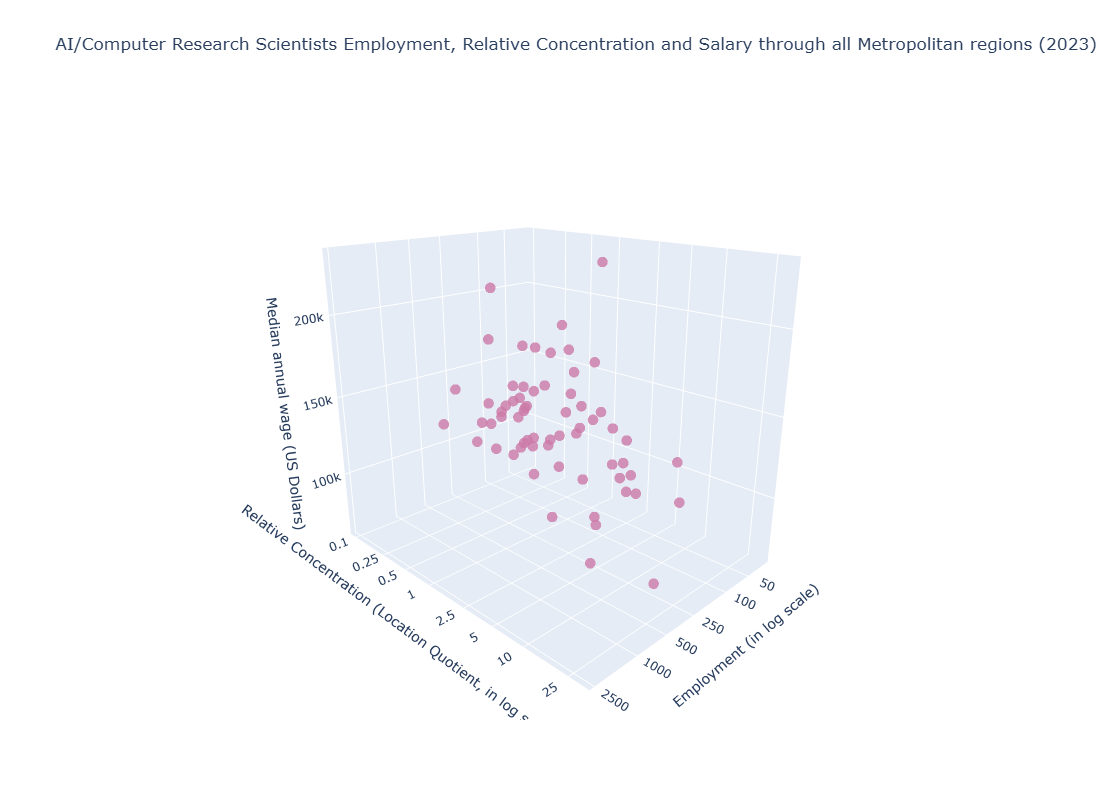

In [105]:
#Preparing the Data for the 3D plot. 

role_3d = "AI/Computer Research Scientists"

metropolitan = metropolitans[metropolitans['ROLE'] == role_3d].dropna(subset=['LOC_QUOTIENT', 'TOT_EMP', 'A_MEDIAN'])
print(metropolitan.shape)

#Plotting the chart itself
#the 3 axis are defined as the total employment, the concentration of the chosen occupation relative to its national concentration, 
#and the median salary nationally. 
#The colour of the points is defined as the colour of the category that occupation is part of, 
#solely for consistency. 
scatter_3d_fig = px.scatter_3d(metropolitan, 
                          x='TOT_EMP',
                          y='LOC_QUOTIENT',
                          z= 'A_MEDIAN', 
                          color='CATEGORY', 
                          color_discrete_map = category_colours,
                          log_x = True,
                          log_y = True, 
                          hover_name='AREA_TITLE',
                          hover_data= {'TOT_EMP': ':,', 'A_MEDIAN': ':,', 'LOC_QUOTIENT': True, 'CATEGORY': False}, labels = {'TOT_EMP': 'Employment (in log scale)','LOC_QUOTIENT': 'Relative Concentration (Location Quotient, in log scale)','A_MEDIAN': 'Median annual wage (US Dollars)' }, 
                          title= 'AI/Computer Research Scientists Employment, Relative Concentration and Salary through all Metropolitan regions (2023)'
                          )


#Updating chart's size,
scatter_3d_fig.update_traces(marker=dict(size=6, opacity=0.8))
scatter_3d_fig.update_layout(height=800, 
                             showlegend=False, 
                             scene_camera=dict(eye=dict(x=1.6, y=1.6, z=0.8)),
                             scene=dict(xaxis=dict(tickvals=[50, 100, 250, 500, 1000, 2500]), 
                                        yaxis=dict(tickvals=[0.1, 0.25, 0.5, 1, 2.5, 5, 10, 25])))


scatter_3d_fig.show()

- Objective, Justification and Learning:
This plot serves solely as a visual support for the previous two-dimensional scatter plot 3.5. I have chosen the AI/Computer Research occupation given that it exhibits an interesting behaviour: a moderately strong correlation when it comes to employment (workforce size) and salary across metropolitan areas, but a very weak negative correlation between concentration and wage.
The 3D visualisation of this scatter plot allows for a clearer visualisation of the weaker (almost non-existent) and negative correlation: the projected plane composed by Median Salary and Employment, exhibits a pattern of points scattered loosely around an ascending line. However, when the figure is spun to project a plane composed by Concentration and Salary, the points are more dramatically scattered, and it is even hard to identify any correlation (although the mathematics show that there is a slight negative one). This 3D chart also allows for a better visualisation of the correlation between Concentration and Employment, which are positively correlated, although weakly. 

4. Challenge Task: Time Series of Occupations relating to Software, Data and AI (from 2015 to 2025)

In [111]:
#Loading the new Data 
#I have renamed each file as national_{year} - this will make it easy to loop through
#rather than hard coding each name

data_years = list(range(2015, 2026))
year_data = []

for year in data_years:
    current_df = pd.read_excel(f'national_{year}.xlsx')
    #in the next line, I convert the column names to upper case
    #the BLS has not been consistent with their naming
    #By checking the tables, I noticed many of them had lower case in some years and 
    #upper in others
    current_df.columns = current_df.columns.str.upper()
    #In the next column I rename the column OCC_GROUP, to the newer title O_GROUP
    #again fixing an inconsistency problem from BLS
    current_df = current_df.rename(columns={'OCC_GROUP':'O_GROUP'})
    #In the next line, I am creating a column to register the year
    #this allow me to identify the year from which every row came
    current_df['YEAR'] = year
    year_data.append(current_df)
    print(year, current_df.shape)
                                   


2015 (1394, 21)
2016 (1394, 21)
2017 (1382, 21)
2018 (1379, 21)
2019 (1329, 31)
2020 (1329, 32)
2021 (1403, 33)
2022 (1402, 33)
2023 (1403, 33)
2024 (1403, 33)
2025 (1401, 33)


In [112]:
#Now in this cell, I am going to combine the data coming from all of the different years.

complete_df = pd.concat(year_data, ignore_index=True)
print(complete_df.shape)
print(complete_df.columns.tolist())
complete_df.head()



(15219, 33)
['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY', 'YEAR', 'AREA', 'AREA_TITLE', 'AREA_TYPE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PRIM_STATE', 'PCT_RPT']


,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,...,AREA_TYPE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PRIM_STATE,PCT_RPT
0,00-0000,All Occupations,total,137896660,0.1,23.23,48320,0.1,9.07,11.27,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11-0000,Management Occupations,major,6936990,0.2,55.3,115020,0.1,22.29,32.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11-1000,Top Executives,minor,2439900,0.2,59.71,124210,0.2,20.47,31.39,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11-1010,Chief Executives,broad,238940,0.7,89.35,185850,0.4,32.98,53.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11-1011,Chief Executives,detailed,238940,0.7,89.35,185850,0.4,32.98,53.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [116]:
#Now I am going to test if the data consists of the expected for the national data
#which is expected to have only rows pertaining to cross-industry and US national area
#hence, by printing a value counts of I_GROUP and AREA_TYPE I should only get\
#cross-industry results, NaN and 1. 
print(complete_df['I_GROUP'].value_counts(dropna=False))
print(complete_df['AREA_TYPE'].value_counts(dropna=False))

I_GROUP
cross-industry    9670
NaN               5549
Name: count, dtype: int64
AREA_TYPE
1.0    9670
NaN    5549
Name: count, dtype: int64


In [117]:
#Another problem with the data is that BLS has changed their standards in 2018
#Some of the occupations had different codes before 2018, hence it is necessary to check
#which codes were being used depending on the year analysed. 
#By checking the table descriptions and the tables themselves, I was able to identify
#that tech-related occupations started with 15-, even in older tables 
#Hence, I will check all tech occupations for their codes:

techno_df = complete_df[(complete_df['OCC_CODE'].str.startswith('15-')) & (complete_df['O_GROUP'] == 'detailed')]
techno_df


,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,...,AREA_TYPE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PRIM_STATE,PCT_RPT
131,15-1111,Computer and Information Research Scientists,detailed,25510,3.9,55.57,115580,1.5,30.91,41.62,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
133,15-1121,Computer Systems Analysts,detailed,556660,1.1,43.36,90180,0.4,24.96,31.89,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
134,15-1122,Information Security Analysts,detailed,88880,2.1,44.83,93250,0.6,24.65,32.64,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
136,15-1131,Computer Programmers,detailed,289420,1.7,40.56,84360,1.4,21.37,28.97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
137,15-1132,"Software Developers, Applications",detailed,747730,1.4,49.12,102160,1.1,27.57,36.14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13975,15-2021,Mathematicians,detailed,2030,2.5,62.15,129260,1.0,33.29,42.58,...,1.0,0.0,Cross-industry,cross-industry,1235.0,NaN,NaN,NaN,US,NaN
13977,15-2031,Operations Research Analysts,detailed,108510,1.4,47.95,99730,0.6,27.43,32.86,...,1.0,0.0,Cross-industry,cross-industry,1235.0,NaN,NaN,NaN,US,NaN
13979,15-2041,Statisticians,detailed,29030,2.7,55.63,115700,1.2,30.77,39.53,...,1.0,0.0,Cross-industry,cross-industry,1235.0,NaN,NaN,NaN,US,NaN
13981,15-2051,Data Scientists,detailed,262440,1.1,60.96,126800,0.7,32.33,41.18,...,1.0,0.0,Cross-industry,cross-industry,1235.0,NaN,NaN,NaN,US,NaN


In [118]:
#To make it easier to see the code data changing overtime, I wanted find a way to cross year data (
#which is why I created the year column) with code data.
#I found this method in Pandas (n.d.)'s documentation, using .crosstab. 
#if the value is 1, that code is present in that year, when the value is 0, it is not. 


pd.crosstab(techno_df['OCC_CODE'], techno_df['YEAR'])

YEAR,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
OCC_CODE,,,,,,,,,,,
15-1111,1,1,1,1,0,0,0,0,0,0,0
15-1121,1,1,1,1,0,0,0,0,0,0,0
15-1122,1,1,1,1,0,0,0,0,0,0,0
15-1131,1,1,1,1,0,0,0,0,0,0,0
15-1132,1,1,1,1,0,0,0,0,0,0,0
15-1133,1,1,1,1,0,0,0,0,0,0,0
15-1134,1,1,1,1,0,0,0,0,0,0,0
15-1141,1,1,1,1,0,0,0,0,0,0,0
15-1142,1,1,1,1,0,0,0,0,0,0,0


In [119]:
pd.crosstab(techno_df['OCC_TITLE'], techno_df['YEAR'])

YEAR,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
OCC_TITLE,,,,,,,,,,,
Actuaries,1,1,1,1,1,1,1,1,1,1,1
Computer Network Architects,1,1,1,1,1,1,1,1,1,1,1
Computer Network Support Specialists,1,1,1,1,1,1,1,1,1,1,1
"Computer Occupations, All Other",1,1,1,1,1,1,1,1,1,1,1
Computer Programmers,1,1,1,1,1,1,1,1,1,1,1
Computer Systems Analysts,1,1,1,1,1,1,1,1,1,1,1
Computer User Support Specialists,1,1,1,1,1,1,1,1,1,1,1
Computer and Information Research Scientists,1,1,1,1,1,1,1,1,1,1,1
Data Scientists,0,0,0,0,0,0,1,1,1,1,1


By using the two tables generated above, I could list all of the occupations that have had a code change, but no other modification;  as well as occupations which were not on the list before the reformulation of the standards (like Data Scientists, 15-2051, which was only introduced in SOC 2018 and only in a separate code in 2021). Some Occupations have been merged or split with others, like Software Developers and QA, that was split into two separate occupations after 2018. For that reason, the time series will have to be adapted to each different scenario: 

Occupations that have remained stable (either have had the same code all throughout or have had only one code change with no other modifications. They will be listed here with the titles I have been using for them in this assignment, rather than strictly the title they exhibit on the table): 
Statisticians; Operations Research Analysts; Computer Programmers; Information Security Analysts; Computer Systems Analysts and AI/Computer Research Scientists. 
For these occupations, all years are usable. 

Occupations that have been either devided or combined: 
Web Developers and Digital Designers; Database Administrators and Database Architects; And Software Developers and Software QA and Testers.
For this occupations, 2019 - 2025 can be used with no problems. However, from 2015 to 2018, they were summed under a different code, this will need to be dealt with (for example, for occupations that were combined under a different code, I can sum the two new codes into one category, creating a consistent pattern that can be analysed in time). 

Occupation created in 2021: Data Scientist. Can be used consistently after 2021. 

Another important detail to think about: while employment totals can be added up, when it comes to previously combined occupations, the salaries on the table are medians, hence they cannot be added up. To avoid these issues, I have decided to create a time series using solely the occupations which have exhibited consistent representation by BLS.

In [121]:
#preparing the data: converting columns types to number (float), reusing the same
#method from step 2

for column in ['TOT_EMP', 'A_MEDIAN']:
    complete_df[column] = complete_df[column].map(make_number)

#Checking if it works:
print(complete_df[['TOT_EMP', 'A_MEDIAN']].dtypes)

TOT_EMP     float64
A_MEDIAN    float64
dtype: object


In [122]:
#In this cell, using the knowledge I gathered from the cross tables 
#I will map each code to the occupation titles, to create usable data for my time series

time_roles_codes = {
    '15-1111': 'AI/Computer Research Scientists', '15-1221': 'AI/Computer Research Scientists', 
    '15-1121': 'Computer Systems Analysts', '15-1211': 'Computer Systems Analysts', 
    '15-1122': 'Information Security Analysts', '15-1212': 'Information Security Analysts', 
    '15-1131': 'Computer Programmers', '15-1251': 'Computer Programmers',
    '15-2031': 'Operations Research Analysts', 
    '15-2041': 'Statisticians', 
    '15-1132': 'Software Developers and QA Testers', '15-1133': 'Software Developers and QA Testers',
    '15-1256': 'Software Developers and QA Testers', 
    '15-1252': 'Software Developers and QA Testers', '15-1253': 'Software Developers and QA Testers', 
    '15-1141': 'Database Administrators and Architects', '15-1245': 'Database Administrators and Architects',
    '15-1242':  'Database Administrators and Architects', '15-1243':  'Database Administrators and Architects',
    '15-1134': 'Web Developers and Digital Designers', '15-1257': 'Web Developers and Digital Designers',
    '15-1254': 'Web Developers and Digital Designers', '15-1255':'Web Developers and Digital Designers',
    '15-2051': 'Data Scientists'
}

stable_occ = ['AI/Computer Research Scientists', 'Computer Systems Analysts', 'Information Security Analysts',  
             'Computer Programmers', 'Operations Research Analysts', 'Statisticians']

#Keeping only the tech-related roles, by using the keys of my dictionary list
#as a filter: I am only keeping the rows containing those particular OCC_CODES
only_tech = complete_df[(complete_df['O_GROUP'] == 'detailed') & (complete_df['OCC_CODE'].isin(time_roles_codes.keys()))].copy()


only_tech['ROLES_TIME_SERIES'] = only_tech['OCC_CODE'].map(time_roles_codes)

#printing table shape, checking for duplicated rows (That should not happen, cause
#I built the table as per no year has the same code appearing 2 times. 
print(only_tech.shape)
print(only_tech.duplicated(subset=['YEAR', 'OCC_CODE']).sum())

(123, 34)
0


In [124]:
#Creating the employment time series data and checking it by isolating the 2023 numbers, which I can compare to 
#my previous data. this confirms that the data from the national tables match the files 
#containing all data. 
employment_time_series = only_tech.groupby(['ROLES_TIME_SERIES', 'YEAR'], as_index=False)['TOT_EMP'].sum()
employment_time_series[employment_time_series['YEAR'] == 2023]


,ROLES_TIME_SERIES,YEAR,TOT_EMP
8,AI/Computer Research Scientists,2023,35210.0
19,Computer Programmers,2023,120370.0
30,Computer Systems Analysts,2023,498810.0
35,Data Scientists,2023,192710.0
46,Database Administrators and Architects,2023,136060.0
57,Information Security Analysts,2023,175350.0
68,Operations Research Analysts,2023,117880.0
79,Software Developers and QA Testers,2023,1859920.0
90,Statisticians,2023,29950.0
101,Web Developers and Digital Designers,2023,196410.0


4.1 Time Series Visualisation 1: Growth in Employment 2015-2025 

In this visualisation, I am displaying the growth in employment for all 6 stable occupations. The occupations which have not remained stable in representation by the BLS during the 11 years analysed would show a false increase  after 2019, given that they were being undercounted from 2015 to 2018. 


AI/Computer Research Scientists | 2015 employment: 25510.0 | 2025 index: 145.8
Computer Systems Analysts | 2015 employment: 556660.0 | 2025 index: 93.3
Information Security Analysts | 2015 employment: 88880.0 | 2025 index: 214.5
Computer Programmers | 2015 employment: 289420.0 | 2025 index: 31.9
Operations Research Analysts | 2015 employment: 95860.0 | 2025 index: 113.2
Statisticians | 2015 employment: 29870.0 | 2025 index: 97.2


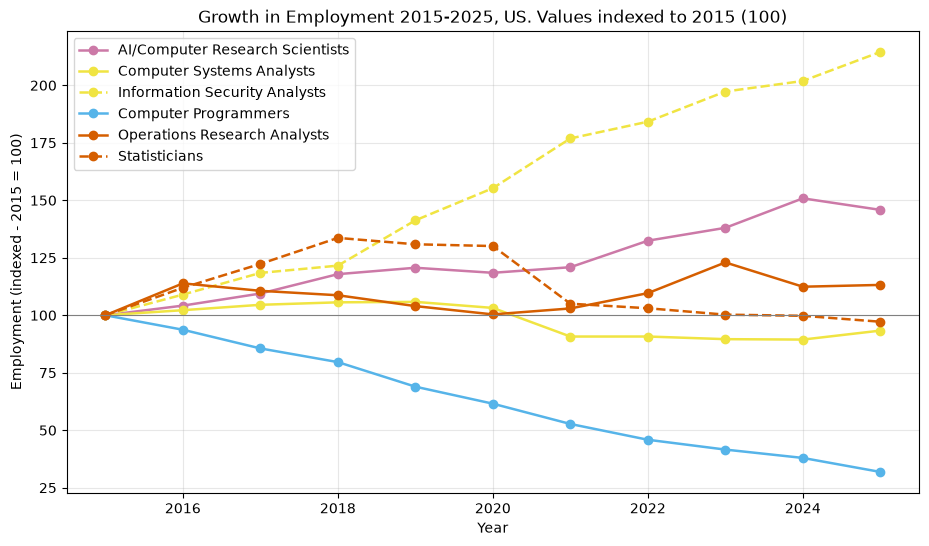

In [126]:
#Creating a dictionary with the style for each line. 
#In the for loop, I will refer back to this dictionary, specifying index of
#of the style object to be used. 
style = {
    'AI/Computer Research Scientists': ['#CC79A7', '-', 1.8],
    'Computer Systems Analysts': ['#F0E442', '-', 1.8], 
    'Information Security Analysts': ['#F0E442', '--', 1.8], 
    'Computer Programmers': ['#56B4E9', '-', 1.8], 
    'Operations Research Analysts': ['#D55E00', '-', 1.8], 
    'Statisticians': ['#D55E00', '--', 1.8]
}

#stablishing the figure size. 
plt.figure(figsize=(11,6))

#The actual plot
#with a for loop, I loop through stable occupations list and use it
#to select from employment_time_series where ROLE_TIME_SERIES matches the value from 
#the stable occupations list. 
for occ in stable_occ:
    occ_data = employment_time_series[employment_time_series['ROLES_TIME_SERIES'] == occ]
    b_2015 = occ_data[occ_data['YEAR'] == 2015]['TOT_EMP'].sum()
    #Indexing the values to the employment in 2015, stablishing that year as 100
    index_values = occ_data['TOT_EMP'] / b_2015 * 100
    plt.plot(occ_data['YEAR'], index_values, color= style[occ][0], linestyle= style[occ][1],linewidth = style[occ][2], marker='o', label=occ)
    print(occ, '| 2015 employment:', b_2015, '| 2025 index:', round(index_values.iloc[-1], 1))

#Defining the reference line as being in the value 100 and its style
plt.axhline(100, color='grey', linewidth=0.8)
#Title and labels 
plt.title( "Growth in Employment 2015-2025, US. Values indexed to 2015 (100)")
plt.xlabel('Year')
plt.ylabel('Employment (indexed - 2015 = 100)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()



Objective: with this plot, I have aimed to observe how each one of the occupations that remained consistently represented in BLS's table (amounting to 6) have evolved over 11 years (2015-2025) in terms of employment growth. 

Justification: 
1. I have used a line chart given that it is the ideal approach to show change over time: the year dots connected by the line represent trends very visually. This was the same type of chart taught in class for stock prices' changes.
2. I have indexed employment to the 2015 values, given that the actual employment numbers differ greatly from one occupation to another (for example, there were less than 26 000 AI/Computer Research Scientists in 2015, while Computer Programmers amounted to almost 300 000 workers). It is, therefore, very important to highlight that this chart does not display absolute numbers, but rather compares the growth of each occupation, and each growth is calculated comparing the occupation with itself. The absolute values and the end index for each occupation can be found above the chart.
3. The colours for each line still represent to which category that occupation belongs, maintaining consistency with previous charts. Occupations within the same category, hence, with the same colour, are differentiated by line style.

Learning: 
1. The occupation which exhibited a steeper growth was Information Security Analysts. It reached a final index of 214.5. In absolute numbers, that represents a growth of almost 102 000 workers. It is important to notice, however, that the chart shows a big growth after BLS's changes to their code standards, which could indicate that the growth is partially due to reclassification.
2. In contrast with the other occupations, Computer Programmers exhibited a continuous decline in employment, year after year. The occupation lost about 197 000 workers. However that does not mean that the activity itself is in decline, it is possible that workers in similar functions are labeled under different titles, like software developers etc.
3. When it comes to Statisticians, the trend is interesting and connects to a previous conjecture I made in this assignment: that people working as Data Scientists might have been labeled under different titles traditionally. The Data Scientist occupation OCC_CODE was included in 2021: from 2020 to 2021, there is a rapid decline in Statisticians, which might suggest that this is due to a reclassification of Statisticians into the new occupation title. More evidence to that claim is that between 2015 and 2020, this occupation had exhibited a steady growth (2015-2018) and a slight decline (2018-2020), followed by the dramatic change from 2020 to 2021.
4. AI/Computer Research Scientists displayed the second biggest growth in relative terms. Their ending index was of 145.8. However, because this occupation is relatively small, when compared to the others, the absolute number of workers that caused this growth is relatively low (about 11 700 workers).
5. The trend, in general, exhibits a growth specially in areas pertaining security and research, while programming saw a steep decline (although, I have mentioned that these workers have probably been labeled under different titles). The Data-related jobs tracked in this chart have seen a slight decline (-2.8% for statisticians) or a moderate growth (Operations Research Analysts) in employment.

   

4.1.1 Supporting chart: Data Scientists vs Statisticians

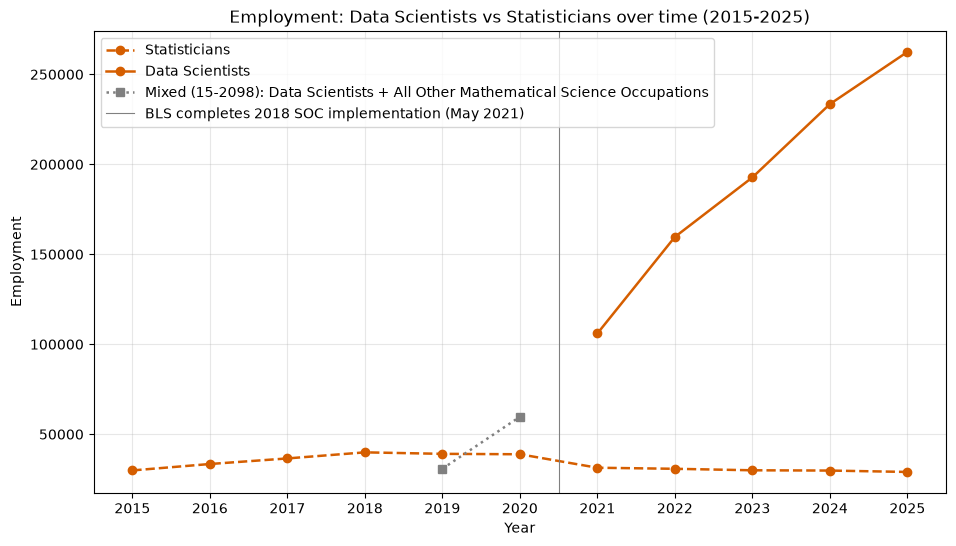

ROLES_TIME_SERIES  YEAR  TOT_EMP
    Statisticians  2015  29870.0
    Statisticians  2016  33440.0
    Statisticians  2017  36540.0
    Statisticians  2018  39920.0
    Statisticians  2019  39090.0
    Statisticians  2020  38860.0
    Statisticians  2021  31370.0
    Statisticians  2022  30780.0
    Statisticians  2023  29950.0
    Statisticians  2024  29800.0
    Statisticians  2025  29030.0
ROLES_TIME_SERIES  YEAR  TOT_EMP
  Data Scientists  2021 105980.0
  Data Scientists  2022 159630.0
  Data Scientists  2023 192710.0
  Data Scientists  2024 233440.0
  Data Scientists  2025 262440.0
                                                      OCC_TITLE  YEAR  TOT_EMP
Data Scientists and Mathematical Science Occupations, All Other  2019  30810.0
Data Scientists and Mathematical Science Occupations, All Other  2020  59680.0


In [129]:
statisticians = employment_time_series[employment_time_series['ROLES_TIME_SERIES'] == 'Statisticians']
data_scientists = employment_time_series[employment_time_series['ROLES_TIME_SERIES'] == 'Data Scientists']
mixed = complete_df[complete_df['OCC_CODE'] == '15-2098']

plt.figure(figsize=(11, 6))

plt.plot(statisticians['YEAR'], statisticians['TOT_EMP'], color= '#D55E00', linestyle='--', linewidth = 1.8, marker='o', label='Statisticians')
plt.plot(data_scientists['YEAR'], data_scientists['TOT_EMP'], color= '#D55E00', linestyle='-', linewidth = 1.8, marker='o', label='Data Scientists')
plt.plot(mixed['YEAR'], mixed['TOT_EMP'], color= 'grey', linestyle=':', linewidth = 1.8, marker='s', label='Mixed (15-2098): Data Scientists + All Other Mathematical Science Occupations')

plt.axvline(2020.5, color='grey', linewidth=0.8, label='BLS completes 2018 SOC implementation (May 2021)')

plt.title('Employment: Data Scientists vs Statisticians over time (2015-2025)')
plt.xlabel('Year')
plt.ylabel('Employment')
plt.xticks(data_years)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(statisticians[['ROLES_TIME_SERIES', 'YEAR', 'TOT_EMP']].to_string(index=False))
print(data_scientists[['ROLES_TIME_SERIES', 'YEAR', 'TOT_EMP', ]].to_string(index=False))
print(mixed[['OCC_TITLE', 'YEAR', 'TOT_EMP']].to_string(index=False))

Objective and learning:
1. With this time series chart I wanted to investigate further if the creation of Data Scientist as an occupation title in BLS's 2018 SOC had an influence on the decline of employment for Statisticians occupation registered in the previous time series chart.
2. This chart allowed me to clearly see that, in fact, the fall in statisticians employment coincides with the inclusion of Data Scientists in the 2018 SOC, however, that fall amounts to a loss of approximately 7 500 workers. Meanwhile, when Data Scientists were included in the standards, they are in 2021 already 105 980 workers. Hence, the employment decline in statisticians can only explain, in the most extreme scenario (every Statistician lost for reclassification as Data Scientist), about 7% of the Data Scientist numbers.
3. The Data Scientists numbers cannot be explained by the mixed classification either. Data Scientists and all Other Mathematical Occupations accounted for 59680 jobs in 2020, which is still very low compared to the initial number of Data Scientists. What most likely happened is that Data scientists partially drew workers from Statisticians, from Data Scientists and Mathematical Science Occupations, but also from other mixed classifications like "Computer Occupations, All Other", which were left out of this chart for conciseness.
4. The steep growth in Data Science jobs after 2021 can only be explained by external factors pertaining the job market, given that it is much more accentuated than the stable and very slight decline in Statistician employment.
5. A limitation of analysing this chart and data specifically is that one cannot fully stablish a causality, given that individual worker's movements are not registered, but rather the totals in employment for each occupation at a given time. Any relationship between the lines is inferred and must not be taken as raw facts.
   

5. Bibliography:
Ahmed, T. (2026) Duplicates and outliers [Jupyter Notebook]. Data Visualisation. CCT College Dublin. Available at: CCT College Dublin Moodle (Accessed: 13/10/2026).

Cinus, F., Septiandri, A., Constantinides, M. and Quercis, D. (2025) 'Measuring how computer science research translates into innovation and development', EPJ Data Science, 14, Article 51. Available at 
https://doi.org/10.1140/epjds/s13688-025-00568-. Accessed: 22/10/20264

Naval Facilities Engineering Systems Command (n.d.) Naval Support Facility Dahlgren. Available at: https://www.navfac.navy.mil/Divisions/Environmental/Products-and-Services/Environmental-Restoration/Washington/Dahlgren-NSF/ (Accessed: 13/10/2026).

Okabe, M. and Ito, K. (2008) Color Universal Design (CUD): colorblind barrier free. Available at: https://jfly.uni-koeln.de/color/ (Accessed: 13/10/2026).

Pandas (n.d.). Pandas.Crosstab — Pandas 1.2.4 documentation. [online] pandas.pydata.org. Available at: https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html [Accessed 31 Oct. 2026].

Ravulakollu, N. (2023). 3 Best ways to handle right skewed data. [online] AlmaBetter. Available at: https://www.almabetter.com/bytes/articles/3-best-ways-to-handle-right-skewed-data [Accessed 3 Nov. 2026].

Spence, I. (2005) 'No humble pie: the origins and usage of statistical chart', Journal of Educational and Behavioral Statistics, vol. 30, no. 4, pp. 353-368, doi: 10.3102/10769986030004353

U.S. Bureau of Labor Statistics (2018) 2018 Standard Occupational Classification System: major groups. Available at: https://www.bls.gov/soc/2018/major_groups.htm (Accessed: 13/10/2026).

U.S. Bureau of Labor Statistics (2024a) May 2023 occupational employment and wage estimates: all data [Dataset]. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 15 October 2026).

U.S. Bureau of Labor Statistics (2024b) Technical notes for May 2023 OEWS estimates. Available at: https://www.bls.gov/oes/2023/May/oes_tec.htm (Accessed: 15/10/2026).

v-s-labs (2016). Improper alignment of boxplots in facets. [online] GitHub. Available at: https://github.com/plotly/plotly.R/issues/697 [Accessed 1 Nov. 2026].

Washington State Employment Security Department (n.d.) Occupational employment and wage statistics (OEWS). Available at: https://esd.wa.gov/jobs-and-training/labor-market-information/employment-and-wages/occupational-employment-and-wage-statistics-oews [Accessed: 15 October 2026].